# inferlab – Labor

Dieses Notebook geht einmal durch das ganze Projekt. Jedes Kapitel des Skripts
bekommt einen eigenen Abschnitt, und jeder Abschnitt hat dieselben drei Schritte:

1. **Erklären** – was das Verfahren tut und wozu man es braucht
2. **Prüfen** – stimmen die inferlab-Zahlen mit `scipy`/`statsmodels` und mit den Werten aus dem Skript überein?
3. **Zeigen** – eine Grafik, die das Verfahren anschaulich macht

Im zweiten Teil wird nicht mehr nachgerechnet, sondern **nachgezählt**: Das
Simulationslabor wiederholt Experimente tausendfach mit Daten, bei denen die
Wahrheit bekannt ist, und schaut, ob die Theorie hält, was sie verspricht.

| Teil I – Die Werkzeuge | Teil II – Das Simulationslabor |
|---|---|
| 1. Die Datensätze aus dem Skript | 10. Wird der Schätzer mit mehr Daten besser? |
| 2. Schätzen | 11. Halten 95 %-Intervalle ihr Versprechen? |
| 3. Konfidenzintervalle | 12. Wie oft findet ein Test einen echten Effekt? |
| 4. Tests mit einer Stichprobe | 13. Was passiert, wenn die Annahmen nicht stimmen? |
| 5. Zwei Stichproben vergleichen | 14. Grenzwertsätze als Bild |
| 6. Mehrere Gruppen vergleichen | 15. Bootstrap gegen klassisch |
| 7. Regression | 16. Ungleiche Streuungen: Welch gegen gepoolt |
| 8. Häufigkeitstafeln | 17. Viele Vergleiche, viele Fehlalarme |
| 9. Verfahren ohne Normalverteilung | Zum Schluss: Prüfprotokoll |

Alle Rechnungen stecken in `inferlab`. Das Notebook ruft nur auf, prüft und zeichnet.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

from inferlab.datasets import (
    load_emergencyroom, load_rutherford, load_iq, load_reactiontime, load_ptca,
)
from inferlab.estimation import (
    ml_estimate, moment_estimate, bayes_binomial, bayes_normal,
)
from inferlab.intervals import (
    ci_mean_known_sigma, ci_mean_unknown_sigma, ci_variance,
    bootstrap_percentile_ci, bootstrap_t_ci_mean,
)
from inferlab.hypothesis_tests import (
    gauss_test, t_test, variance_test, log_likelihood, likelihood_ratio_test,
    two_sample_t_test, welch_test, f_test, paired_t_test,
)
from inferlab.anova import one_way_anova, bonferroni_pairwise, tukey_hsd
from inferlab.regression import (
    linear_regression, coefficient_standard_errors, coefficient_tests,
    r_squared, overall_f_test, ci_mean_response, prediction_interval,
)
from inferlab.categorical import chi_squared_independence_test, fisher_exact_test
from inferlab.nonparametric import (
    index_of_dispersion_test, sign_test, chi_squared_goodness_of_fit,
    wilcoxon_rank_sum_test,
)
from inferlab import simulate as sim

### Werkzeugkasten für das Notebook

Hilfen, damit die Kapitel übersichtlich bleiben:

- **Farben und Stil** – eine feste Farbreihenfolge, damit dieselbe Rolle überall dieselbe Farbe hat
  (Blau = unser Ergebnis/Gruppe 1, Orange = Vergleich/Gruppe 2, Rot nur für „verfehlt“ oder „abgelehnt“).
- **`check`** – vergleicht einen Wert von uns mit einer Referenz und trägt das Ergebnis ins Prüfprotokoll ein.
- **`shade_p_value`** – zeichnet die Verteilung unter H₀ und färbt die Fläche ein, die den p-Wert bildet.

In [ ]:
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
MAGENTA, GREEN, VIOLET = "#e87ba4", "#008300", "#6250d6"
MISS = "#d03b3b"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#dedcd6"

plt.rcParams.update({
    "figure.figsize": (13, 4),
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET]),
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 2, "lines.markersize": 7,
    "legend.frameon": False, "font.size": 10.5, "figure.dpi": 100,
})

# Zufallszahlen: Jedes Kapitel setzt seine eigene feste Quelle (rng bzw. sim_rng).
# So bleiben die Beispiele gleich, auch wenn ein Kapitel davor mehr oder weniger Zufall verbraucht.

# Prüfprotokoll
protocol = []

def check(label, ours, reference, rel=1e-9, abs_=0.0):
    # Vergleicht unseren Wert mit einer Referenz und protokolliert das Ergebnis.
    ours_arr = np.atleast_1d(np.asarray(ours, dtype=float))
    ref_arr = np.atleast_1d(np.asarray(reference, dtype=float))
    ok = bool(np.allclose(ours_arr, ref_arr, rtol=rel, atol=abs_))
    fmt = lambda a: ", ".join(f"{v:.6g}" for v in a)
    protocol.append((label, ok, fmt(ours_arr), fmt(ref_arr)))
    print(f"{'✓' if ok else '✗'}  {label:<52} ours {fmt(ours_arr):<26} ref {fmt(ref_arr)}")
    return ok

def check_true(label, condition, detail=""):
    # Für Eigenschaften statt Zahlen ("liegt im Intervall", "ist kleiner als" ...).
    ok = bool(condition)
    protocol.append((label, ok, detail, "Eigenschaft"))
    print(f"{'✓' if ok else '✗'}  {label:<52} {detail}")
    return ok

# p-Wert als Fläche
def shade_p_value(ax, distribution, statistic, alternative="two_sided",
                  grid=None, title=None, stat_name="Teststatistik"):
    if grid is None:
        lo, hi = distribution.ppf(0.0005), distribution.ppf(0.9995)
        lo, hi = min(lo, -abs(statistic) * 1.1, statistic), max(hi, abs(statistic) * 1.1, statistic)
        grid = np.linspace(lo, hi, 600)
    dens = distribution.pdf(grid)
    ax.plot(grid, dens, color=MUTED, lw=1.8, label="Verteilung unter H₀")
    if alternative == "greater":
        tails = [grid >= statistic]
    elif alternative == "less":
        tails = [grid <= statistic]
    else:
        mirror = distribution.ppf(distribution.sf(statistic)) if distribution.cdf(statistic) > 0.5 \
            else distribution.isf(distribution.cdf(statistic))
        tails = [grid >= max(statistic, mirror), grid <= min(statistic, mirror)]
    for i, mask in enumerate(tails):
        ax.fill_between(grid, 0, dens, where=mask, color=ORANGE, alpha=0.55,
                        label="Fläche = p-Wert" if i == 0 else None)
    ax.axvline(statistic, color=BLUE, lw=2, label=f"beobachtet: {statistic:.3g}")
    ax.set_xlabel(stat_name); ax.set_ylabel("Dichte"); ax.set_ylim(bottom=0)
    if title: ax.set_title(title)
    ax.legend(fontsize=9)

---
# Teil I – Die Werkzeuge

## 1. Die Datensätze aus dem Skript

`datasets.py` liefert die fünf Beispiele aus der Vorlesung. Sie sind von sehr
unterschiedlicher Art, und genau das macht sie nützlich:

- **Viele Daten, Zählwerte:** Rutherford – 2608 Zeitintervalle mit der Anzahl radioaktiver Zerfälle
- **Wenige Daten, Wartezeiten:** Notaufnahme – 10 Zeitabstände zwischen ankommenden Patienten
- **Nur Kennzahlen, keine Rohdaten:** IQ (bekannte Verteilung) und Reaktionszeiten (Mittelwert und Streuung je Gruppe)
- **Eine Häufigkeitstafel:** PTCA – Behandlungserfolg mit und ohne früheren Herzinfarkt

In [5]:
rutherford = load_rutherford("raw")
rutherford_table = load_rutherford("table")
emergency = load_emergencyroom()
iq = load_iq()
reaction_phone, reaction_radio = load_reactiontime()
ptca = load_ptca()

check("Rutherford: Anzahl Intervalle", len(rutherford), 2608)
check("Rutherford: Mittelwert (Skript 3.87)", round(rutherford.mean(), 2), 3.87)
check("Notaufnahme: Mittelwert (32.9 min)", round(emergency.mean(), 1), 32.9)
check("PTCA: Gesamtzahl Patienten", ptca.sum(), 131)

✓  Rutherford: Anzahl Intervalle                        ours 2608                       ref 2608
✓  Rutherford: Mittelwert (Skript 3.87)                 ours 3.87                       ref 3.87
✓  Notaufnahme: Mittelwert (32.9 min)                   ours 32.9                       ref 32.9
✓  PTCA: Gesamtzahl Patienten                           ours 131                        ref 131


True

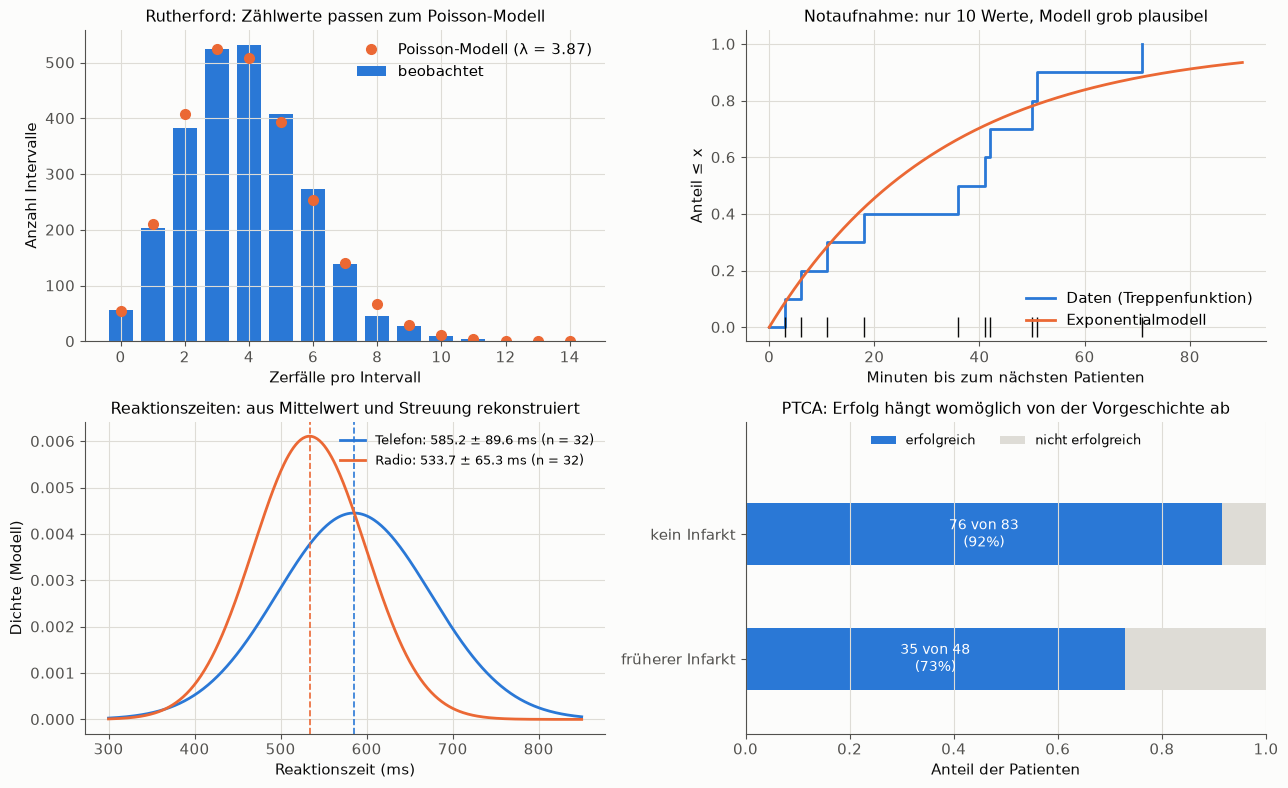

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# Rutherford: beobachtete Häufigkeiten gegen Poisson-Modell
ax = axes[0, 0]
k = np.arange(0, 15)
observed = np.array([rutherford_table.get(i, 0) for i in k])
lam = rutherford.mean()
ax.bar(k, observed, color=BLUE, width=0.75, label="beobachtet")
ax.plot(k, len(rutherford) * stats.poisson.pmf(k, lam), "o", color=ORANGE,
        label=f"Poisson-Modell (λ = {lam:.2f})")
ax.set_xlabel("Zerfälle pro Intervall"); ax.set_ylabel("Anzahl Intervalle")
ax.set_title("Rutherford: Zählwerte passen zum Poisson-Modell"); ax.legend()

# Notaufnahme: empirische Verteilungsfunktion gegen Exponentialmodell
ax = axes[0, 1]
x_sorted = np.sort(emergency)
ax.step(np.r_[0, x_sorted], np.arange(len(x_sorted) + 1) / len(x_sorted),
        where="post", color=BLUE, label="Daten (Treppenfunktion)")
grid = np.linspace(0, 90, 300)
ax.plot(grid, stats.expon.cdf(grid, scale=emergency.mean()), color=ORANGE,
        label="Exponentialmodell")
ax.plot(x_sorted, np.zeros_like(x_sorted), "|", color=INK, ms=14)
ax.set_xlabel("Minuten bis zum nächsten Patienten"); ax.set_ylabel("Anteil ≤ x")
ax.set_title("Notaufnahme: nur 10 Werte, Modell grob plausibel"); ax.legend(loc="lower right")

# Reaktionszeiten: nur Kennzahlen, also Normalmodell pro Gruppe
ax = axes[1, 0]
grid = np.linspace(300, 850, 400)
for group, label, color in [(reaction_phone, "Telefon", BLUE), (reaction_radio, "Radio", ORANGE)]:
    ax.plot(grid, stats.norm.pdf(grid, group.mu, group.sigma), color=color,
            label=f"{label}: {group.mu} ± {group.sigma} ms (n = {group.group_size})")
    ax.axvline(group.mu, color=color, ls="--", lw=1.2)
ax.set_xlabel("Reaktionszeit (ms)"); ax.set_ylabel("Dichte (Modell)")
ax.set_title("Reaktionszeiten: aus Mittelwert und Streuung rekonstruiert"); ax.legend(fontsize=9)

# PTCA: Erfolgsquote je Gruppe
ax = axes[1, 1]
groups = ["früherer Infarkt", "kein Infarkt"]
success_share = ptca[:, 0] / ptca.sum(axis=1)
bars = ax.barh(groups, success_share, color=BLUE, height=0.5, label="erfolgreich")
ax.barh(groups, 1 - success_share, left=success_share, color=GRID, height=0.5,
        label="nicht erfolgreich")
for i, (share, row) in enumerate(zip(success_share, ptca)):
    ax.text(share / 2, i, f"{row[0]} von {row.sum()}\n({share:.0%})", ha="center",
            va="center", color="white", fontsize=10)
ax.set_xlim(0, 1); ax.set_ylim(-0.6, 1.9); ax.set_xlabel("Anteil der Patienten")
ax.set_title("PTCA: Erfolg hängt womöglich von der Vorgeschichte ab")
ax.legend(loc="upper center", ncol=2, fontsize=9); ax.grid(axis="y", visible=False)

plt.tight_layout(); plt.show()

Schon der erste Blick zeigt, welche Fragen die späteren Kapitel beantworten:
Passt das Poisson-Modell wirklich zu Rutherford (Kapitel 9)? Reagieren Fahrer
mit Telefon langsamer (Kapitel 5)? Und ist der Unterschied bei PTCA mehr als
Zufall (Kapitel 8)?

---
## 2. Schätzen

Ein Modell hat unbekannte Stellschrauben (Parameter), etwa die mittlere Zerfallsrate λ.
`estimation.py` bietet drei Wege, sie aus Daten zu bestimmen:

- **Maximum-Likelihood (ML):** Welcher Parameterwert macht die beobachteten Daten am wahrscheinlichsten?
  Allgemein umgesetzt: Die Funktion schlägt die passende Dichte in einer Tabelle nach und lässt den Optimierer suchen.
- **Momentenmethode:** Theoretischen Mittelwert (bzw. Streuung) mit dem beobachteten gleichsetzen und auflösen.
- **Bayes:** Vorwissen (Prior) mit den Daten verrechnen.

### 2.1 ML und Momente im Vergleich

Für die vier Verteilungen in der Tabelle gibt es auch eine Lösung per Hand.
Der Optimierer muss sie treffen.

In [7]:
rng = np.random.default_rng(2)
iq_sample = rng.normal(iq.mu, iq.sigma, 50)
geometric_sample = rng.geometric(0.3, 500) - 1      # Fehlversuche vor dem ersten Erfolg

cases = {
    "Poisson – Rutherford":     (rutherford, "poisson",
                                 [rutherford.mean()]),
    "Exponential – Notaufnahme": (emergency, "exponential",
                                 [1 / emergency.mean()]),
    "Normal – IQ-Stichprobe":   (iq_sample, "normal",
                                 list(stats.norm.fit(iq_sample))),
    "Geometrisch – simuliert":  (geometric_sample, "geometric",
                                 [1 / (1 + geometric_sample.mean())]),
}

for label, (data, distribution, closed_form) in cases.items():
    check(f"ML  {label}", ml_estimate(data, distribution), closed_form, rel=1e-4)
    check(f"Mom {label}", moment_estimate(data, distribution), closed_form, rel=1e-10)

✓  ML  Poisson – Rutherford                             ours 3.87155                    ref 3.87155
✓  Mom Poisson – Rutherford                             ours 3.87155                    ref 3.87155
✓  ML  Exponential – Notaufnahme                        ours 0.0303951                  ref 0.0303951
✓  Mom Exponential – Notaufnahme                        ours 0.0303951                  ref 0.0303951
✓  ML  Normal – IQ-Stichprobe                           ours 100.329, 14.7022           ref 100.329, 14.7022
✓  Mom Normal – IQ-Stichprobe                           ours 100.329, 14.7022           ref 100.329, 14.7022
✓  ML  Geometrisch – simuliert                          ours 0.325521                   ref 0.325521
✓  Mom Geometrisch – simuliert                          ours 0.325521                   ref 0.325521


### 2.2 Wie die Likelihood aussieht

ML sucht den Gipfel der Log-Likelihood. Interessant ist auch die **Form** des Gipfels:
Ein spitzer Gipfel heißt, die Daten legen den Parameter eng fest. Ein flacher Gipfel heißt,
viele Werte sind fast gleich plausibel.

Damit beide Datensätze vergleichbar werden, ist die Kurve so verschoben, dass der Gipfel bei 0 liegt.
Die gestrichelte Linie bei −1.92 markiert grob den Bereich plausibler Werte (das ist das 95 %-Intervall
aus dem Likelihood-Quotienten-Test aus Kapitel 4).

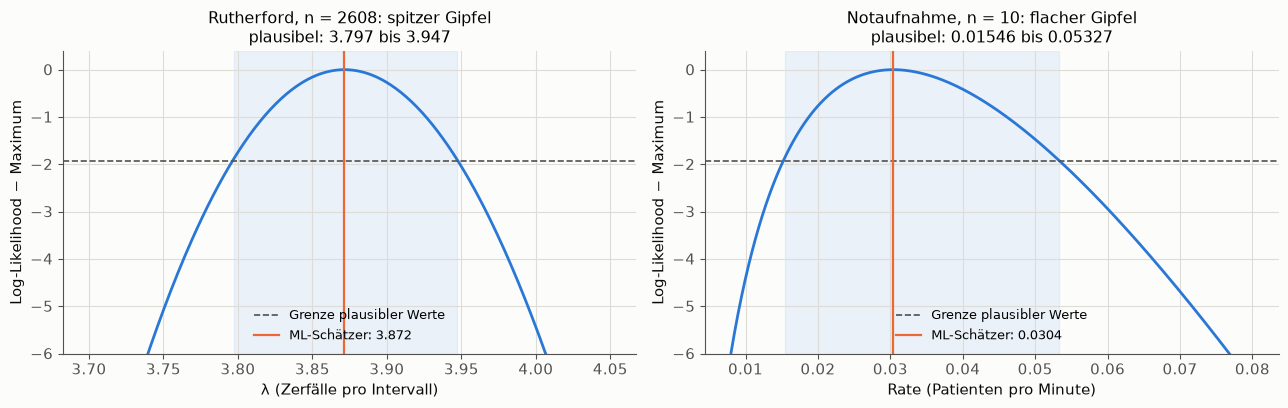

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
cutoff = -stats.chi2.ppf(0.95, df=1) / 2

panels = [
    (axes[0], rutherford, "poisson", np.linspace(3.70, 4.05, 300), "λ (Zerfälle pro Intervall)",
     "Rutherford, n = 2608: spitzer Gipfel"),
    (axes[1], emergency, "exponential", np.linspace(0.008, 0.08, 300), "Rate (Patienten pro Minute)",
     "Notaufnahme, n = 10: flacher Gipfel"),
]
for ax, data, distribution, grid, xlabel, title in panels:
    estimate = ml_estimate(data, distribution)[0]
    curve = np.array([log_likelihood(data, distribution, value) for value in grid])
    peak = log_likelihood(data, distribution, estimate)
    ax.plot(grid, curve - peak, color=BLUE)
    ax.axhline(cutoff, color=MUTED, ls="--", lw=1.2, label="Grenze plausibler Werte")
    inside = grid[curve - peak >= cutoff]
    ax.axvspan(inside.min(), inside.max(), color=BLUE, alpha=0.08)
    ax.axvline(estimate, color=ORANGE, lw=1.6, label=f"ML-Schätzer: {estimate:.4g}")
    ax.set_ylim(-6, 0.4); ax.set_xlabel(xlabel); ax.set_ylabel("Log-Likelihood − Maximum")
    ax.set_title(f"{title}\nplausibel: {inside.min():.4g} bis {inside.max():.4g}")
    ax.legend(loc="lower center", fontsize=9)

plt.tight_layout(); plt.show()

### 2.3 Bayes: Vorwissen und Daten verrechnen

**Erfolgswahrscheinlichkeit (Beta-Binomial).** Angenommen, 7 von 20 Versuchen gelingen.
Wer vorher keine Meinung hat (flacher Prior), landet nahe am Anteil 7/20.
Wer vorher fest von 50 % überzeugt ist, wird nur ein Stück in Richtung der Daten gezogen.
Mit mehr Daten verliert das Vorwissen an Gewicht.

**Mittelwert (Normal-Normal).** Dasselbe Prinzip für einen Mittelwert:
Der Bayes-Schätzer ist ein gewichteter Durchschnitt aus Vorwissen ν und Stichprobenmittel x̄.

In [9]:
x_success, n_trials = 7, 20
priors = {"flach: Beta(1, 1)": (1, 1, BLUE), "skeptisch: Beta(10, 10)": (10, 10, ORANGE)}

# Prüfungen: Posterior-Mittel gegen scipy und gegen Grenzfälle
for label, (a, b, _) in priors.items():
    check(f"Beta-Binomial, {label}", bayes_binomial(x_success, n_trials, a, b),
          stats.beta(a + x_success, b + n_trials - x_success).mean())

prior_mean, prior_sd, sigma_known = 100.0, 5.0, 15.0
iq_group = rng.normal(110, sigma_known, 200)          # Gruppe mit wahrem Mittel 110
precision_form = ((prior_mean / prior_sd**2 + len(iq_group) * iq_group.mean() / sigma_known**2)
                  / (1 / prior_sd**2 + len(iq_group) / sigma_known**2))
check("Normal-Normal gegen Präzisionsformel",
      bayes_normal(iq_group, sigma_known, prior_mean, prior_sd), precision_form)
check("Normal-Normal: sehr vages Vorwissen → x̄",
      bayes_normal(iq_group, sigma_known, prior_mean, 1e6), iq_group.mean(), rel=1e-8)
check("Normal-Normal: sehr festes Vorwissen → ν",
      bayes_normal(iq_group, sigma_known, prior_mean, 1e-6), prior_mean, rel=1e-8)

✓  Beta-Binomial, flach: Beta(1, 1)                     ours 0.363636                   ref 0.363636
✓  Beta-Binomial, skeptisch: Beta(10, 10)               ours 0.425                      ref 0.425
✓  Normal-Normal gegen Präzisionsformel                 ours 109.22                     ref 109.22
✓  Normal-Normal: sehr vages Vorwissen → x̄             ours 109.634                    ref 109.634
✓  Normal-Normal: sehr festes Vorwissen → ν             ours 100                        ref 100


True

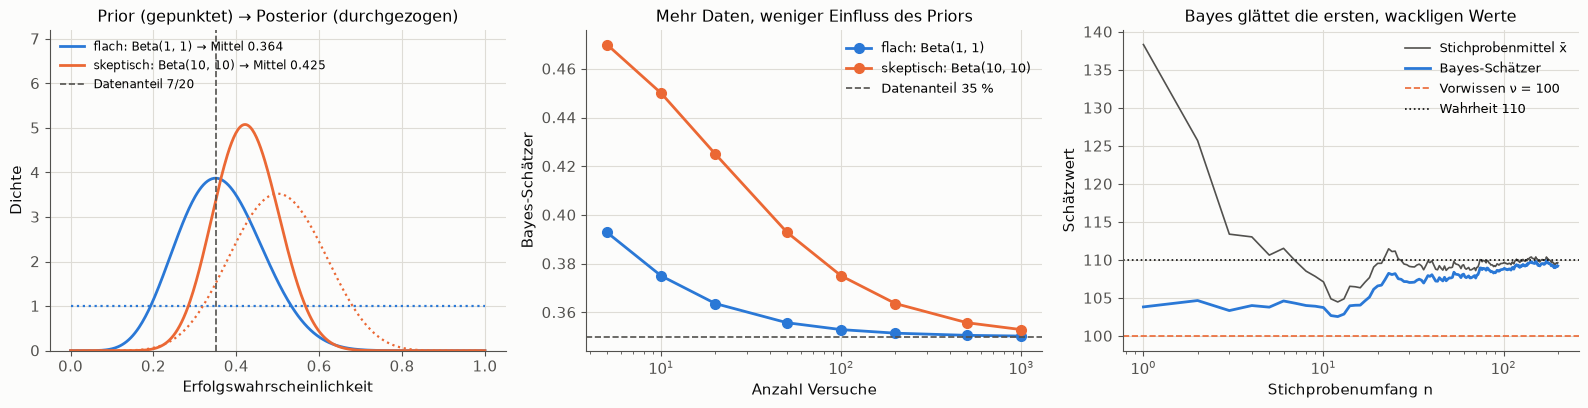

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# links: Prior und Posterior für beide Vorannahmen
ax = axes[0]
p = np.linspace(0, 1, 400)
for label, (a, b, color) in priors.items():
    ax.plot(p, stats.beta(a, b).pdf(p), color=color, ls=":", lw=1.6)
    ax.plot(p, stats.beta(a + x_success, b + n_trials - x_success).pdf(p), color=color,
            label=f"{label} → Mittel {bayes_binomial(x_success, n_trials, a, b):.3f}")
ax.axvline(x_success / n_trials, color=MUTED, ls="--", lw=1.2, label="Datenanteil 7/20")
ax.set_xlabel("Erfolgswahrscheinlichkeit"); ax.set_ylabel("Dichte")
ax.set_ylim(0, 7.2)
ax.set_title("Prior (gepunktet) → Posterior (durchgezogen)"); ax.legend(fontsize=8.5, loc="upper left")

# mitte: mit wachsendem n setzen sich die Daten durch (Anteil fest bei 35 %)
ax = axes[1]
ns = np.array([5, 10, 20, 50, 100, 200, 500, 1000])
for label, (a, b, color) in priors.items():
    ax.plot(ns, [bayes_binomial(0.35 * n, n, a, b) for n in ns], "o-", color=color, label=label)
ax.axhline(0.35, color=MUTED, ls="--", lw=1.2, label="Datenanteil 35 %")
ax.set_xscale("log"); ax.set_xlabel("Anzahl Versuche"); ax.set_ylabel("Bayes-Schätzer")
ax.set_title("Mehr Daten, weniger Einfluss des Priors"); ax.legend(fontsize=9)

# rechts: Normal-Normal, Schätzer entlang wachsender Stichprobe
ax = axes[2]
sizes = np.arange(1, len(iq_group) + 1)
running_mean = np.cumsum(iq_group) / sizes
bayes_path = [bayes_normal(iq_group[:n], sigma_known, prior_mean, prior_sd) for n in sizes]
ax.plot(sizes, running_mean, color=MUTED, lw=1.2, label="Stichprobenmittel x̄")
ax.plot(sizes, bayes_path, color=BLUE, label="Bayes-Schätzer")
ax.axhline(prior_mean, color=ORANGE, ls="--", lw=1.2, label="Vorwissen ν = 100")
ax.axhline(110, color=INK, ls=":", lw=1.2, label="Wahrheit 110")
ax.set_xscale("log"); ax.set_xlabel("Stichprobenumfang n"); ax.set_ylabel("Schätzwert")
ax.set_title("Bayes glättet die ersten, wackligen Werte"); ax.legend(fontsize=9)

plt.tight_layout(); plt.show()

Rechts sieht man den praktischen Nutzen: Bei den ersten Beobachtungen springt das
Stichprobenmittel stark, der Bayes-Schätzer bleibt dank Vorwissen ruhig. Ab einigen
Dutzend Beobachtungen laufen beide zusammen. Das Vorwissen hat seinen Dienst getan.

---
## 3. Konfidenzintervalle

Ein Schätzwert allein sagt nicht, wie genau er ist. Ein Konfidenzintervall gibt einen Bereich an,
der den wahren Wert mit vorgegebener Sicherheit (hier 95 %) einschließt.
`intervals.py` bietet zwei Familien:

- **Mit Formel** (setzen Normalverteilung voraus): Mittelwert bei bekannter Streuung (z), bei unbekannter Streuung (t), Varianz (χ²)
- **Per Bootstrap** (ohne Verteilungsannahme): Die Stichprobe wird tausendfach neu „gezogen“, die Streuung der Ergebnisse ersetzt die Formel.
  Zwei Varianten: Perzentil und Bootstrap-t.

Grundlage ist eine IQ-Stichprobe mit n = 25 und wahrem Mittel 100.

In [11]:
rng = np.random.default_rng(3)
sample = rng.normal(iq.mu, iq.sigma, 25)
m, s, n = sample.mean(), sample.std(ddof=1), len(sample)

ci = {
    "z (σ bekannt)":      ci_mean_known_sigma(mean=m, sigma=iq.sigma, n=n, confidence_level=0.95),
    "t (σ unbekannt)":    ci_mean_unknown_sigma(mean=m, s=s, n=n, confidence_level=0.95),
    "Bootstrap-Perzentil": bootstrap_percentile_ci(sample, np.mean, 4000, 0.95, rng),
    "Bootstrap-t":        bootstrap_t_ci_mean(sample, 4000, 0.95, rng),
}
var_ci = ci_variance(s=s, n=n, confidence_level=0.95)

check("z-Intervall gegen scipy", ci["z (σ bekannt)"],
      stats.norm.interval(0.95, loc=m, scale=iq.sigma / np.sqrt(n)))
check("t-Intervall gegen scipy", ci["t (σ unbekannt)"],
      stats.t.interval(0.95, df=n - 1, loc=m, scale=s / np.sqrt(n)))
chi_lo, chi_hi = stats.chi2.interval(0.95, df=n - 1)
check("Varianz-Intervall gegen χ²-Quantile", var_ci,
      ((n - 1) * s**2 / chi_hi, (n - 1) * s**2 / chi_lo))
scipy_boot = stats.bootstrap((sample,), np.mean, n_resamples=4000, method="percentile",
                             confidence_level=0.95, random_state=1).confidence_interval
check("Bootstrap-Perzentil gegen scipy (Zufall: ±1)", ci["Bootstrap-Perzentil"],
      (scipy_boot.low, scipy_boot.high), rel=0, abs_=1.0)
check("Bootstrap-t nahe am t-Intervall (±1.5)", ci["Bootstrap-t"],
      ci["t (σ unbekannt)"], rel=0, abs_=1.5)

print(f"\nVarianz: s² = {s**2:.1f}, 95 %-Intervall [{var_ci[0]:.1f}, {var_ci[1]:.1f}] "
      f"(wahr: {iq.sigma**2}) – deutlich unsymmetrisch um s².")

✓  z-Intervall gegen scipy                              ours 93.3878, 105.148           ref 93.3878, 105.148
✓  t-Intervall gegen scipy                              ours 91.9525, 106.583           ref 91.9525, 106.583
✓  Varianz-Intervall gegen χ²-Quantile                  ours 191.482, 607.806           ref 191.482, 607.806
✓  Bootstrap-Perzentil gegen scipy (Zufall: ±1)         ours 92.5578, 106.472           ref 92.5474, 106.261
✓  Bootstrap-t nahe am t-Intervall (±1.5)               ours 92.8426, 107.568           ref 91.9525, 106.583

Varianz: s² = 314.1, 95 %-Intervall [191.5, 607.8] (wahr: 225) – deutlich unsymmetrisch um s².


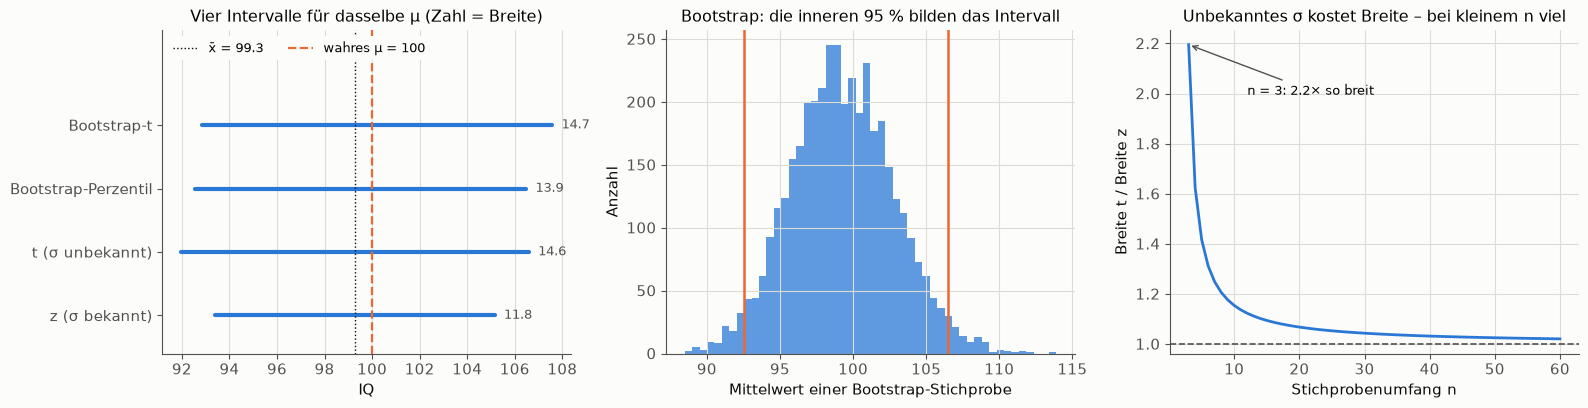

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# links: alle vier Intervalle nebeneinander
ax = axes[0]
for i, (label, (lo, hi)) in enumerate(ci.items()):
    ax.plot([lo, hi], [i, i], color=BLUE, lw=3, solid_capstyle="round")
    ax.text(hi + 0.4, i, f"{hi - lo:.1f}", va="center", color=MUTED, fontsize=9)
ax.axvline(m, color=INK, ls=":", lw=1, label=f"x̄ = {m:.1f}")
ax.axvline(iq.mu, color=ORANGE, ls="--", lw=1.6, label="wahres μ = 100")
ax.set_yticks(range(len(ci))); ax.set_yticklabels(ci.keys()); ax.set_ylim(-0.6, len(ci) + 0.5)
ax.set_xlabel("IQ"); ax.set_title("Vier Intervalle für dasselbe μ (Zahl = Breite)")
ax.legend(fontsize=9, loc="upper left", ncol=2, frameon=True, framealpha=1, edgecolor="none")
ax.grid(axis="y", visible=False)

# mitte: was der Bootstrap intern tut
ax = axes[1]
boot_means = rng.choice(sample, size=(4000, n), replace=True).mean(axis=1)
ax.hist(boot_means, bins=50, color=BLUE, alpha=0.75)
for edge in ci["Bootstrap-Perzentil"]:
    ax.axvline(edge, color=ORANGE, lw=1.8)
ax.set_xlabel("Mittelwert einer Bootstrap-Stichprobe"); ax.set_ylabel("Anzahl")
ax.set_title("Bootstrap: die inneren 95 % bilden das Intervall")

# rechts: der Preis für unbekanntes σ
ax = axes[2]
ns = np.arange(3, 61)
ratio = [np.diff(ci_mean_unknown_sigma(0, 1, k, 0.95))[0] / np.diff(ci_mean_known_sigma(0, 1, k, 0.95))[0]
         for k in ns]
ax.plot(ns, ratio, color=BLUE)
ax.axhline(1, color=MUTED, ls="--", lw=1.2)
ax.annotate(f"n = 3: {ratio[0]:.1f}× so breit", (3, ratio[0]), xytext=(12, ratio[0] - 0.2),
            arrowprops=dict(arrowstyle="->", color=MUTED), fontsize=9)
ax.set_xlabel("Stichprobenumfang n"); ax.set_ylabel("Breite t / Breite z")
ax.set_title("Unbekanntes σ kostet Breite – bei kleinem n viel")

plt.tight_layout(); plt.show()

Rechts steckt eine Lehre, die man leicht übersieht: Muss man die Streuung selbst schätzen,
wird das Intervall breiter, weil eine zweite Unsicherheit dazukommt. Bei n = 3 ist der Aufschlag
enorm, ab etwa n = 30 kaum noch spürbar.

---
## 4. Tests mit einer Stichprobe

Ein Test fragt: Sind die Daten mit einer Behauptung H₀ vereinbar, oder ist die Abweichung zu groß für Zufall?
Der **p-Wert** ist die Wahrscheinlichkeit, unter H₀ ein mindestens so extremes Ergebnis zu sehen.
Alle Tests in `hypothesis_tests.py` teilen sich dafür eine Hilfsfunktion `p_value`.

- **Mittelwert:** Gauß-Test (σ bekannt), t-Test (σ unbekannt)
- **Streuung:** χ²-Varianztest
- **Allgemein:** Likelihood-Quotienten-Test – funktioniert für jede Verteilung aus der Schätz-Tabelle

Eine Brücke zu Kapitel 3 dient als besonders strenge Prüfung: **Ein Test verwirft genau dann nicht,
wenn der getestete Wert im Konfidenzintervall liegt.**

In [13]:
t_stat, t_p = t_test(mean=m, mu0=100, s=s, n=n, alternative="two_sided")
reference = stats.ttest_1samp(sample, 100)
check("t-Test gegen scipy: Statistik", t_stat, reference.statistic)
check("t-Test gegen scipy: p-Wert", t_p, reference.pvalue)

for alt in ["two_sided", "greater", "less"]:
    z, p = gauss_test(mean=m, mu0=100, sigma=iq.sigma, n=n, alternative=alt)
    expected = {"two_sided": 2 * stats.norm.sf(abs(z)), "greater": stats.norm.sf(z),
                "less": stats.norm.cdf(z)}[alt]
    check(f"Gauß-Test, Alternative {alt}", p, expected)

# Brücke Test ↔ Intervall, über ein ganzes Raster von Testwerten
mu_grid = np.linspace(85, 115, 301)
t_lo, t_hi = ci["t (σ unbekannt)"]
agree = [(t_test(m, mu0, s, n)[1] >= 0.05) == (t_lo <= mu0 <= t_hi) for mu0 in mu_grid]
check_true("t-Test ↔ t-Intervall: 301 Testwerte", all(agree), "Entscheidung immer gleich")
sigma_grid = np.linspace(8, 30, 221)
agree = [(variance_test(s, s0, n)[1] >= 0.05) == (var_ci[0] <= s0**2 <= var_ci[1]) for s0 in sigma_grid]
check_true("Varianztest ↔ Varianz-Intervall: 221 Testwerte", all(agree), "Entscheidung immer gleich")
check("p-Wert am Intervallrand = 0.05", t_test(m, t_hi, s, n)[1], 0.05, rel=1e-8)

# Likelihood-Quotienten-Test: Rutherford, H0: λ = 4
w, w_p = likelihood_ratio_test(rutherford, "poisson", 4.0)
x_bar, n_r = rutherford.mean(), len(rutherford)
closed = 2 * n_r * (x_bar * np.log(x_bar / 4.0) - (x_bar - 4.0))
check("LQ-Test Poisson gegen geschlossene Formel", w, closed, rel=1e-6)
print(f"\nRutherford, H0: λ = 4 → W = {w:.2f}, p = {w_p:.2e}")

✓  t-Test gegen scipy: Statistik                        ours -0.206603                  ref -0.206603
✓  t-Test gegen scipy: p-Wert                           ours 0.838063                   ref 0.838063
✓  Gauß-Test, Alternative two_sided                     ours 0.80716                    ref 0.80716
✓  Gauß-Test, Alternative greater                       ours 0.59642                    ref 0.59642
✓  Gauß-Test, Alternative less                          ours 0.40358                    ref 0.40358
✓  t-Test ↔ t-Intervall: 301 Testwerte                  Entscheidung immer gleich
✓  Varianztest ↔ Varianz-Intervall: 221 Testwerte       Entscheidung immer gleich
✓  p-Wert am Intervallrand = 0.05                       ours 0.05                       ref 0.05
✓  LQ-Test Poisson gegen geschlossene Formel            ours 10.8748                    ref 10.8748

Rutherford, H0: λ = 4 → W = 10.87, p = 9.75e-04


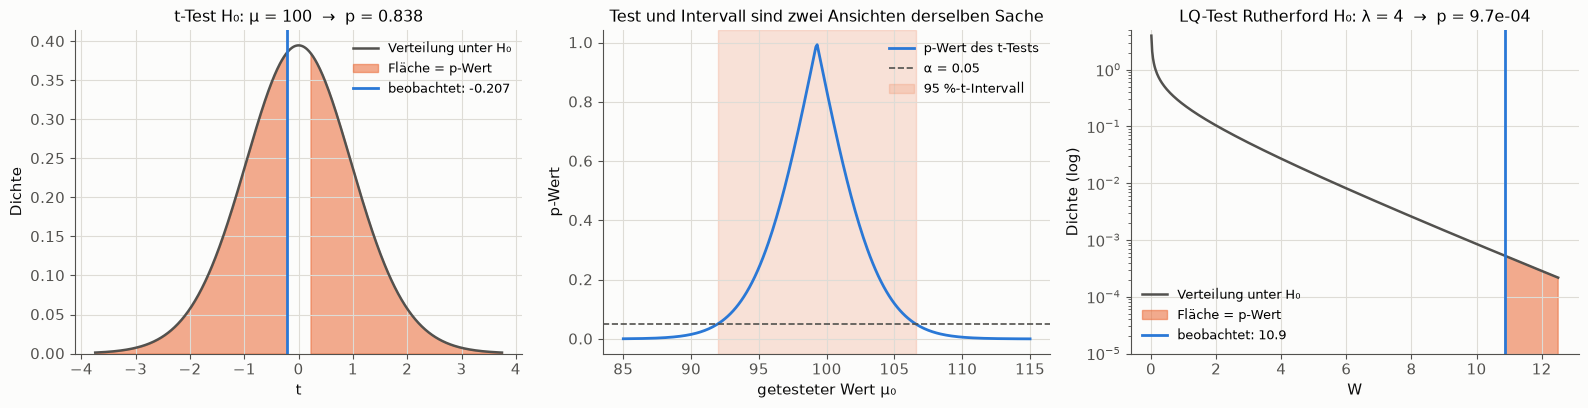

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

shade_p_value(axes[0], stats.t(df=n - 1), t_stat, "two_sided", stat_name="t",
              title=f"t-Test H₀: μ = 100  →  p = {t_p:.3f}")

# mitte: p-Wert als Funktion des getesteten Werts
ax = axes[1]
p_curve = [t_test(m, mu0, s, n)[1] for mu0 in mu_grid]
ax.plot(mu_grid, p_curve, color=BLUE, label="p-Wert des t-Tests")
ax.axhline(0.05, color=MUTED, ls="--", lw=1.2, label="α = 0.05")
ax.axvspan(t_lo, t_hi, color=ORANGE, alpha=0.18, label="95 %-t-Intervall")
ax.set_xlabel("getesteter Wert μ₀"); ax.set_ylabel("p-Wert")
ax.set_title("Test und Intervall sind zwei Ansichten derselben Sache"); ax.legend(fontsize=9)

shade_p_value(axes[2], stats.chi2(df=1), w, "greater", grid=np.linspace(0.01, max(12, w * 1.15), 500),
              stat_name="W", title=f"LQ-Test Rutherford H₀: λ = 4  →  p = {w_p:.1e}")
axes[2].set_yscale("log"); axes[2].set_ylim(1e-5, 5); axes[2].set_ylabel("Dichte (log)")

plt.tight_layout(); plt.show()

Die mittlere Grafik ist das wichtigste Bild des Kapitels: Wo die blaue Kurve über
der gestrichelten Linie liegt, wird nicht verworfen, und genau dort liegt das Intervall.

Rechts der LQ-Test: Bei 2608 Beobachtungen ist λ = 4 deutlich zu weit weg von λ̂ ≈ 3.87.
Das passt zur Likelihood-Kurve in 2.2, deren plausibler Bereich bei etwa 3.80 bis 3.95 lag.

---
## 5. Zwei Stichproben vergleichen

Haben zwei Gruppen denselben Mittelwert? Welcher Test passt, hängt vom Versuchsaufbau ab:

- **Zwei getrennte Gruppen:** Zwei-Stichproben-t-Test (gleiche Streuung angenommen) oder Welch-Test (ohne diese Annahme);
  der F-Test prüft, ob die Streuungen gleich sind
- **Dieselben Personen zweimal gemessen:** gepaarter t-Test – er arbeitet mit den Differenzen

Prüfstein ist das Reaktionszeiten-Beispiel aus dem Skript: **T = 2.63, p = 0.0108**.

In [15]:
g1, g2 = reaction_phone, reaction_radio
args = dict(mean1=g1.mu, s1=g1.sigma, n1=g1.group_size, mean2=g2.mu, s2=g2.sigma, n2=g2.group_size)

T, T_p = two_sample_t_test(**args, alternative="two_sided")
check("Reaktionszeiten: T (Skript 2.63)", T, 2.63, rel=0, abs_=0.005)
check("Reaktionszeiten: p (Skript 0.0108)", T_p, 0.0108, rel=0, abs_=0.0002)

reference = stats.ttest_ind_from_stats(g1.mu, g1.sigma, g1.group_size,
                                       g2.mu, g2.sigma, g2.group_size, equal_var=True)
check("2-Stichproben-t gegen scipy", (T, T_p), (reference.statistic, reference.pvalue))
W_t, W_p = welch_test(**args)
reference = stats.ttest_ind_from_stats(g1.mu, g1.sigma, g1.group_size,
                                       g2.mu, g2.sigma, g2.group_size, equal_var=False)
check("Welch-Test gegen scipy", (W_t, W_p), (reference.statistic, reference.pvalue))

F, F_p = f_test(s1=g1.sigma, n1=g1.group_size, s2=g2.sigma, n2=g2.group_size)
F_dist = stats.f(g1.group_size - 1, g2.group_size - 1)
check("F-Test gegen F-Verteilung", (F, F_p),
      (g1.sigma**2 / g2.sigma**2, 2 * min(F_dist.sf(F), F_dist.cdf(F))))

# Gepaart: 15 Personen, Messung vor und nach einem Training
rng = np.random.default_rng(5)
before = rng.normal(140, 15, 15)
after = before - 6 + rng.normal(0, 4, 15)
P_t, P_p = paired_t_test(before, after)
reference = stats.ttest_rel(before, after)
check("Gepaarter t-Test gegen scipy", (P_t, P_p), (reference.statistic, reference.pvalue))
_, unpaired_p = two_sample_t_test(before.mean(), before.std(ddof=1), 15,
                                  after.mean(), after.std(ddof=1), 15)
print(f"\nDieselben Daten: gepaart p = {P_p:.2g}, fälschlich ungepaart p = {unpaired_p:.2f}")

✓  Reaktionszeiten: T (Skript 2.63)                     ours 2.62764                    ref 2.63
✓  Reaktionszeiten: p (Skript 0.0108)                   ours 0.0108221                  ref 0.0108
✓  2-Stichproben-t gegen scipy                          ours 2.62764, 0.0108221         ref 2.62764, 0.0108221
✓  Welch-Test gegen scipy                               ours 2.62764, 0.0110414         ref 2.62764, 0.0110414
✓  F-Test gegen F-Verteilung                            ours 1.88274, 0.0830684         ref 1.88274, 0.0830684
✓  Gepaarter t-Test gegen scipy                         ours 10.1337, 7.92216e-08       ref 10.1337, 7.92216e-08

Dieselben Daten: gepaart p = 7.9e-08, fälschlich ungepaart p = 0.17


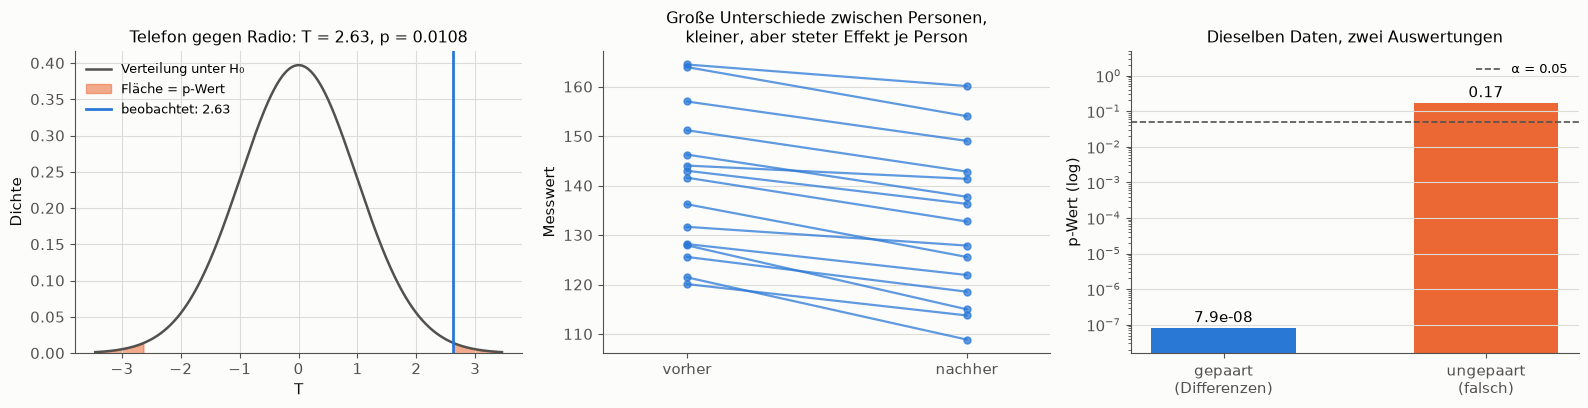

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

shade_p_value(axes[0], stats.t(df=g1.group_size + g2.group_size - 2), T, stat_name="T",
              title=f"Telefon gegen Radio: T = {T:.2f}, p = {T_p:.4f}")

# mitte: gepaarte Daten als Verbindungslinien
ax = axes[1]
for b, a in zip(before, after):
    ax.plot([0, 1], [b, a], color=BLUE if a < b else ORANGE, alpha=0.75, lw=1.6, marker="o", ms=5)
ax.set_xticks([0, 1]); ax.set_xticklabels(["vorher", "nachher"]); ax.set_xlim(-0.3, 1.3)
ax.set_ylabel("Messwert")
ax.set_title("Große Unterschiede zwischen Personen,\nkleiner, aber steter Effekt je Person")
ax.grid(axis="x", visible=False)

# rechts: warum Paarung zählt
ax = axes[2]
bars = ax.bar(["gepaart\n(Differenzen)", "ungepaart\n(falsch)"], [P_p, unpaired_p],
              color=[BLUE, ORANGE], width=0.55)
ax.axhline(0.05, color=MUTED, ls="--", lw=1.2, label="α = 0.05")
ax.set_yscale("log"); ax.set_ylabel("p-Wert (log)"); ax.set_ylim(min(P_p, 0.05) / 5, 5)
for bar, value in zip(bars, [P_p, unpaired_p]):
    ax.text(bar.get_x() + bar.get_width() / 2, value * 1.5, f"{value:.2g}", ha="center")
ax.set_title("Dieselben Daten, zwei Auswertungen"); ax.legend(fontsize=9)
ax.grid(axis="x", visible=False)

plt.tight_layout(); plt.show()

Die rechte Grafik zeigt, warum der Versuchsaufbau in die Auswertung gehört: Der Effekt
ist bei jeder Person klein, aber gleichgerichtet. Der gepaarte Test sieht nur die
Differenzen und erkennt ihn klar. Der ungepaarte Test vergleicht die Gruppen als Ganzes,
dort gehen die wenigen Punkte Effekt im großen Unterschied zwischen Personen unter.

---
## 6. Mehrere Gruppen vergleichen

Bei mehr als zwei Gruppen zerlegt die **Varianzanalyse** die gesamte Streuung in einen Teil
*zwischen* den Gruppen und einen Teil *innerhalb* der Gruppen. Ist der erste Teil groß im
Verhältnis zum zweiten, unterscheiden sich die Gruppen.

Verwirft die ANOVA, folgt die Frage: *Welche* Gruppen unterscheiden sich? Viele Einzelvergleiche
erhöhen die Gefahr von Fehlalarmen. Zwei Korrekturen:

- **Bonferroni:** p-Werte mit der Anzahl Vergleiche multiplizieren – einfach, gilt immer, aber vorsichtig
- **Tukey:** genau für „alle Paare nach einer ANOVA“ gebaut – trennschärfer

Beispiel: Ertrag mit vier Düngemitteln, ungleich große Gruppen.

In [17]:
rng = np.random.default_rng(6)
names = ["A", "B", "C", "D"]
true_means, group_sizes = [20, 21, 26, 20.5], [10, 12, 11, 9]
groups = [rng.normal(mu, 2.5, k) for mu, k in zip(true_means, group_sizes)]

F, F_p = one_way_anova(groups)
reference = stats.f_oneway(*groups)
check("ANOVA gegen scipy", (F, F_p), (reference.statistic, reference.pvalue))

tukey = tukey_hsd(groups)
scipy_tukey = stats.tukey_hsd(*groups)
check("Tukey gegen scipy (alle 6 Paare)", [c.p_value for c in tukey],
      [scipy_tukey.pvalue[c.group1, c.group2] for c in tukey], rel=1e-5)

bonferroni = bonferroni_pairwise(groups)
manual = [min(6 * stats.ttest_ind(groups[c.group1], groups[c.group2]).pvalue, 1) for c in bonferroni]
check("Bonferroni gegen scipy-t-Tests × 6", [c.p_value for c in bonferroni], manual)

t2, _ = two_sample_t_test(groups[0].mean(), groups[0].std(ddof=1), len(groups[0]),
                          groups[1].mean(), groups[1].std(ddof=1), len(groups[1]))
check("Zwei Gruppen: ANOVA-F = t²", one_way_anova(groups[:2])[0], t2**2)

✓  ANOVA gegen scipy                                    ours 8.64923, 0.000167779       ref 8.64923, 0.000167779
✓  Tukey gegen scipy (alle 6 Paare)                     ours 0.999959, 0.00176153, 0.97248, 0.0011886, 0.959072, 0.000664709 ref 0.999959, 0.00176153, 0.97248, 0.0011886, 0.959072, 0.000664709
✓  Bonferroni gegen scipy-t-Tests × 6                   ours 1, 0.00753491, 1, 0.0019921, 1, 0.000930821 ref 1, 0.00753491, 1, 0.0019921, 1, 0.000930821
✓  Zwei Gruppen: ANOVA-F = t²                           ours 0.00200008                 ref 0.00200008


True

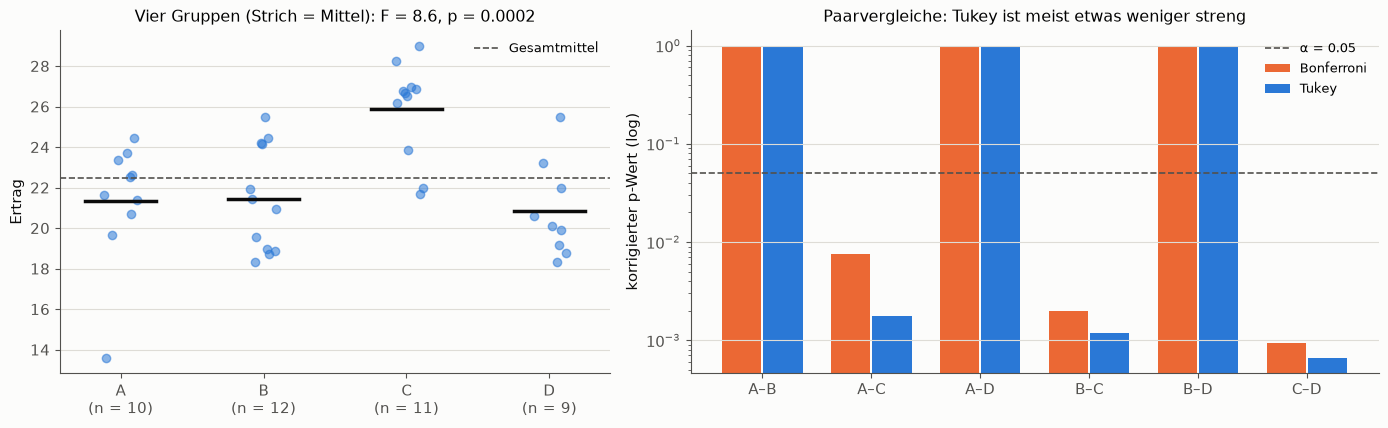

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1.25]})

ax = axes[0]
for i, g in enumerate(groups):
    jitter = rng.uniform(-0.12, 0.12, len(g))
    ax.plot(i + jitter, g, "o", color=BLUE, alpha=0.55, ms=6)
    ax.plot([i - 0.25, i + 0.25], [g.mean()] * 2, color=INK, lw=2.5)
ax.axhline(np.concatenate(groups).mean(), color=MUTED, ls="--", lw=1.2, label="Gesamtmittel")
ax.set_xticks(range(4)); ax.set_xticklabels([f"{name}\n(n = {len(g)})" for name, g in zip(names, groups)])
ax.set_ylabel("Ertrag"); ax.set_title(f"Vier Gruppen (Strich = Mittel): F = {F:.1f}, p = {F_p:.1g}")
ax.legend(fontsize=9); ax.grid(axis="x", visible=False)

ax = axes[1]
labels = [f"{names[c.group1]}–{names[c.group2]}" for c in tukey]
xs = np.arange(len(labels))
ax.bar(xs - 0.19, [c.p_value for c in bonferroni], 0.36, color=ORANGE, label="Bonferroni")
ax.bar(xs + 0.19, [c.p_value for c in tukey], 0.36, color=BLUE, label="Tukey")
ax.axhline(0.05, color=MUTED, ls="--", lw=1.2, label="α = 0.05")
ax.set_yscale("log"); ax.set_xticks(xs); ax.set_xticklabels(labels)
ax.set_ylabel("korrigierter p-Wert (log)")
ax.set_title("Paarvergleiche: Tukey ist meist etwas weniger streng")
ax.legend(fontsize=9); ax.grid(axis="x", visible=False)

plt.tight_layout(); plt.show()

Nur Gruppe C fällt aus der Reihe, und genau die Paare mit C sind signifikant. Die blauen Balken
liegen bei fast allen Paaren unter den orangen: Tukey ist bei derselben Fehlerkontrolle großzügiger.
Wie nötig die Korrektur überhaupt ist, zeigt Untersuchung 17 im Simulationslabor.

---
## 7. Regression

Die lineare Regression legt eine Gerade (oder bei mehreren Einflussgrößen eine Ebene) so durch
die Daten, dass die quadrierten Abstände minimal werden. `regression.py` liefert dazu:

- **Die Gerade selbst** samt Unsicherheit der Koeffizienten und t-Tests je Koeffizient
- **Wie gut sie passt:** R², bereinigtes R² und den F-Test für das Gesamtmodell
- **Vorhersagen:** ein Intervall für die *mittlere* Antwort und ein breiteres für eine *einzelne neue* Beobachtung

Beispiel: Lernstunden und Klausurpunkte für 40 Studierende.

In [19]:
rng = np.random.default_rng(7)
hours = rng.uniform(0, 20, 40)
points = 30 + 2.5 * hours + rng.normal(0, 8, 40)

fit = linear_regression(hours, points)
se = coefficient_standard_errors(fit)
t_values, p_values = coefficient_tests(fit)
r2, r2_adj = r_squared(fit, points)
F, F_p = overall_f_test(fit, points)

reference = stats.linregress(hours, points)
check("Achsenabschnitt, Steigung gegen scipy", fit.coefficients,
      (reference.intercept, reference.slope))
check("Standardfehler gegen scipy", se, (reference.intercept_stderr, reference.stderr))
check("p-Wert der Steigung gegen scipy", p_values[1], reference.pvalue)
check("R² gegen scipy", r2, reference.rvalue**2)
check("Einfache Regression: F = t²", F, t_values[1]**2)

try:
    import statsmodels.api as sm
    model = sm.OLS(points, sm.add_constant(hours)).fit()
    frame = model.get_prediction(np.array([[1.0, 10.0]])).summary_frame(alpha=0.05)
    check("Mittelwert-Intervall bei x = 10 gegen statsmodels", ci_mean_response(fit, 10.0),
          (frame["mean_ci_lower"].iloc[0], frame["mean_ci_upper"].iloc[0]))
    check("Prognose-Intervall bei x = 10 gegen statsmodels", prediction_interval(fit, 10.0),
          (frame["obs_ci_lower"].iloc[0], frame["obs_ci_upper"].iloc[0]))
except ImportError:
    print("statsmodels nicht installiert – Intervall-Vergleich übersprungen")

# Mehrere Einflussgrößen: gegen die Kleinste-Quadrate-Lösung von numpy
sleep = rng.uniform(4, 9, 40)
points_2 = 10 + 2.5 * hours + 4 * sleep + rng.normal(0, 8, 40)
X = np.column_stack([hours, sleep])
fit_2 = linear_regression(X, points_2)
check("Zwei Einflussgrößen gegen numpy lstsq", fit_2.coefficients,
      np.linalg.lstsq(np.column_stack([np.ones(40), X]), points_2, rcond=None)[0])

✓  Achsenabschnitt, Steigung gegen scipy                ours 25.1908, 3.01192           ref 25.1908, 3.01192
✓  Standardfehler gegen scipy                           ours 1.91575, 0.172345          ref 1.91575, 0.172345
✓  p-Wert der Steigung gegen scipy                      ours 9.3038e-20                 ref 9.3038e-20
✓  R² gegen scipy                                       ours 0.889346                   ref 0.889346
✓  Einfache Regression: F = t²                          ours 305.414                    ref 305.414
✓  Mittelwert-Intervall bei x = 10 gegen statsmodels    ours 53.2398, 57.3801           ref 53.2398, 57.3801
✓  Prognose-Intervall bei x = 10 gegen statsmodels      ours 42.117, 68.503             ref 42.117, 68.503
✓  Zwei Einflussgrößen gegen numpy lstsq                ours 8.76234, 2.58721, 3.79973  ref 8.76234, 2.58721, 3.79973


True

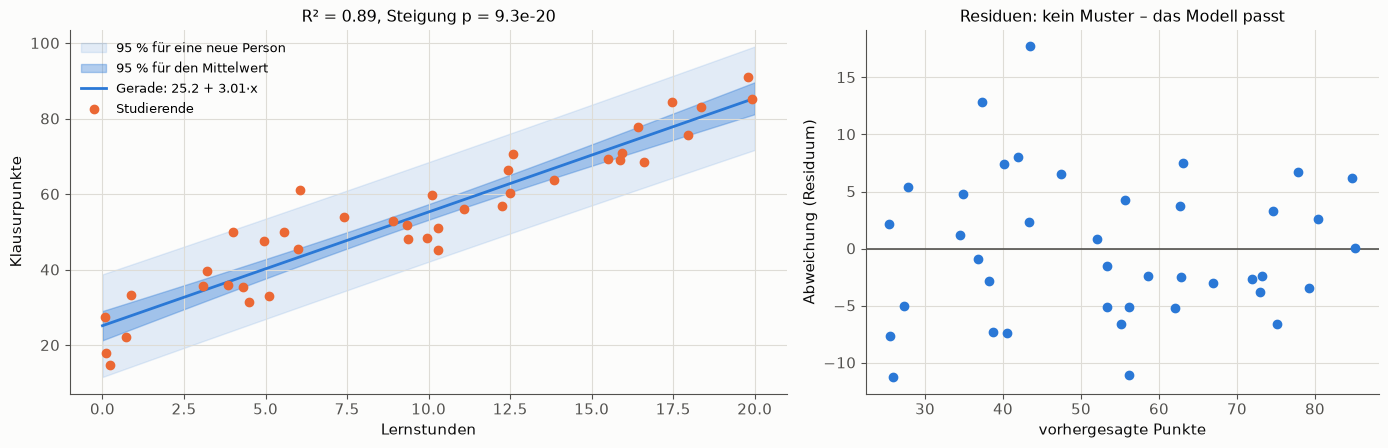

Anteil der Studierenden im Prognose-Band: 98% (erwartet etwa 95 %)


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})

ax = axes[0]
grid = np.linspace(0, 20, 120)
mean_band = np.array([ci_mean_response(fit, x) for x in grid])
pred_band = np.array([prediction_interval(fit, x) for x in grid])
ax.fill_between(grid, pred_band[:, 0], pred_band[:, 1], color=BLUE, alpha=0.12,
                label="95 % für eine neue Person")
ax.fill_between(grid, mean_band[:, 0], mean_band[:, 1], color=BLUE, alpha=0.35,
                label="95 % für den Mittelwert")
ax.plot(grid, fit.coefficients[0] + fit.coefficients[1] * grid, color=BLUE,
        label=f"Gerade: {fit.coefficients[0]:.1f} + {fit.coefficients[1]:.2f}·x")
ax.plot(hours, points, "o", color=ORANGE, ms=6, label="Studierende")
ax.set_xlabel("Lernstunden"); ax.set_ylabel("Klausurpunkte")
ax.set_title(f"R² = {r2:.2f}, Steigung p = {p_values[1]:.1e}")
ax.legend(fontsize=9, loc="upper left")

ax = axes[1]
ax.axhline(0, color=MUTED, lw=1.2)
ax.plot(fit.fitted, fit.residuals, "o", color=BLUE, ms=6)
ax.set_xlabel("vorhergesagte Punkte"); ax.set_ylabel("Abweichung (Residuum)")
ax.set_title("Residuen: kein Muster – das Modell passt")

plt.tight_layout(); plt.show()

inside = np.mean([(lo <= y <= hi) for y, (lo, hi) in
                  zip(points, [prediction_interval(fit, x) for x in hours])])
print(f"Anteil der Studierenden im Prognose-Band: {inside:.0%} (erwartet etwa 95 %)")

Das dunkle Band (Mittelwert) ist schmal und in der Mitte am engsten, weil die Gerade dort
am besten festgelegt ist. Das helle Band (einzelne Person) ist viel breiter, denn hier kommt
die natürliche Streuung der Einzelnen dazu, und die verschwindet auch mit noch so vielen Daten nicht.

---
## 8. Häufigkeitstafeln

Bei der PTCA-Tafel geht es um Anteile statt Mittelwerte: Ist die Erfolgsquote in beiden
Gruppen gleich? `categorical.py` beantwortet das auf zwei Wegen:

- **χ²-Test:** vergleicht beobachtete Häufigkeiten mit denen, die man bei Unabhängigkeit erwarten würde – eine Näherung
- **Fishers exakter Test:** rechnet die Wahrscheinlichkeit direkt aus – exakt, auch bei kleinen Zahlen

Prüfsteine: **X² = 8.1767**, **Fisher p = 0.005824**, und der Wald-Test aus dem Skript (**T = −2.9**),
dessen Quadrat dem χ²-Wert entspricht.

In [21]:
X2, X2_p = chi_squared_independence_test(ptca)
fisher_p = fisher_exact_test(ptca, alternative="two_sided")

check("PTCA: X² (Referenz 8.1767)", X2, 8.1767, rel=0, abs_=5e-5)
check("PTCA: Fisher p (Referenz 0.005824)", fisher_p, 0.005824, rel=0, abs_=5e-7)
reference = stats.chi2_contingency(ptca, correction=False)
check("χ²-Test gegen scipy", (X2, X2_p), (reference.statistic, reference.pvalue))
check("Fisher gegen scipy", fisher_p, stats.fisher_exact(ptca).pvalue)
for alt in ["greater", "less"]:
    check(f"Fisher einseitig ({alt}) gegen scipy", fisher_exact_test(ptca, alt),
          stats.fisher_exact(ptca, alternative=alt).pvalue)

n1, n2 = ptca.sum(axis=1)
p1, p2 = ptca[:, 0] / ptca.sum(axis=1)
p_pool = ptca[:, 0].sum() / ptca.sum()
T_wald = (p1 - p2) / np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
check("Wald-Statistik (Skript −2.9)", round(T_wald, 1), -2.9)
check("Wald-Statistik² = X²", T_wald**2, X2)
expected = np.outer(ptca.sum(axis=1), ptca.sum(axis=0)) / ptca.sum()

✓  PTCA: X² (Referenz 8.1767)                           ours 8.17667                    ref 8.1767
✓  PTCA: Fisher p (Referenz 0.005824)                   ours 0.00582363                 ref 0.005824
✓  χ²-Test gegen scipy                                  ours 8.17667, 0.00424325        ref 8.17667, 0.00424325
✓  Fisher gegen scipy                                   ours 0.00582363                 ref 0.00582363
✓  Fisher einseitig (greater) gegen scipy               ours 0.998895                   ref 0.998895
✓  Fisher einseitig (less) gegen scipy                  ours 0.00516101                 ref 0.00516101
✓  Wald-Statistik (Skript −2.9)                         ours -2.9                       ref -2.9
✓  Wald-Statistik² = X²                                 ours 8.17667                    ref 8.17667


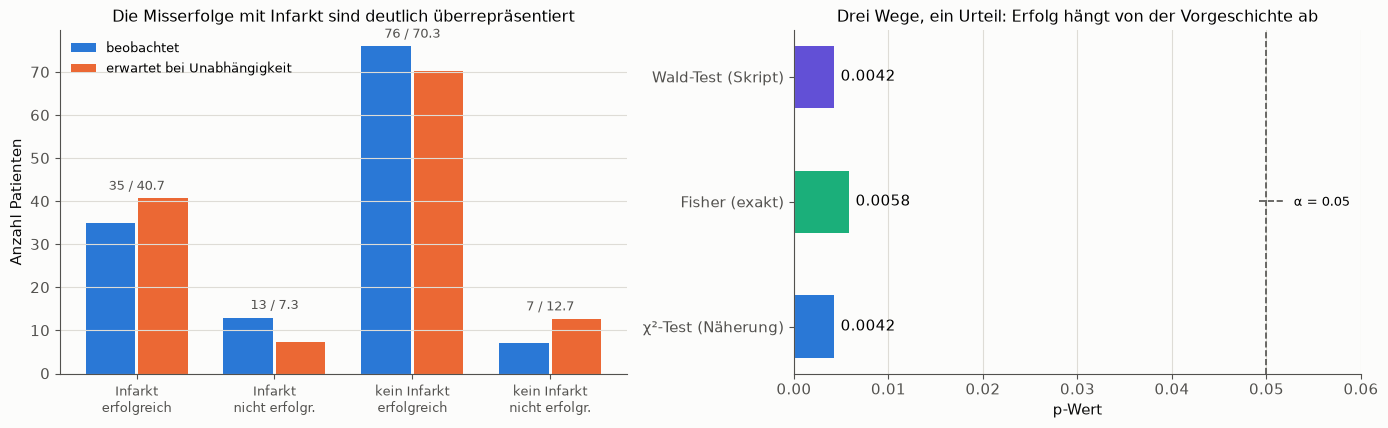

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))

ax = axes[0]
cells = ["Infarkt\nerfolgreich", "Infarkt\nnicht erfolgr.", "kein Infarkt\nerfolgreich", "kein Infarkt\nnicht erfolgr."]
xs = np.arange(4)
ax.bar(xs - 0.19, ptca.ravel(), 0.36, color=BLUE, label="beobachtet")
ax.bar(xs + 0.19, expected.ravel(), 0.36, color=ORANGE, label="erwartet bei Unabhängigkeit")
for x, o, e in zip(xs, ptca.ravel(), expected.ravel()):
    ax.text(x, max(o, e) + 2, f"{o} / {e:.1f}", ha="center", fontsize=9, color=MUTED)
ax.set_xticks(xs); ax.set_xticklabels(cells, fontsize=9)
ax.set_ylabel("Anzahl Patienten"); ax.legend(fontsize=9)
ax.set_title("Die Misserfolge mit Infarkt sind deutlich überrepräsentiert"); ax.grid(axis="x", visible=False)

ax = axes[1]
results = {"χ²-Test (Näherung)": X2_p, "Fisher (exakt)": fisher_p,
           "Wald-Test (Skript)": 2 * stats.norm.sf(abs(T_wald))}
bars = ax.barh(list(results), list(results.values()), color=[BLUE, AQUA, VIOLET], height=0.5)
ax.axvline(0.05, color=MUTED, ls="--", lw=1.2, label="α = 0.05")
for bar, value in zip(bars, results.values()):
    ax.text(value + 0.0007, bar.get_y() + bar.get_height() / 2, f"{value:.4f}", va="center")
ax.set_xlabel("p-Wert"); ax.set_xlim(0, 0.06)
ax.set_title("Drei Wege, ein Urteil: Erfolg hängt von der Vorgeschichte ab")
ax.legend(fontsize=9, loc="center right"); ax.grid(axis="y", visible=False)

plt.tight_layout(); plt.show()

---
## 9. Verfahren ohne Normalverteilung

Viele Tests setzen eine bestimmte Verteilung voraus. `nonparametric.py` sammelt Verfahren,
die das nicht tun oder die gerade prüfen, ob eine Verteilung passt:

- **Passt das Modell?** Dispersionsindex-Test (passt Poisson?) und χ²-Anpassungstest (passen die Häufigkeiten zum Modell?)
- **Lage ohne Verteilungsannahme:** Vorzeichentest (Median) und Wilcoxon-Rangsummentest (zwei Gruppen, arbeitet mit Rängen statt Messwerten)

Prüfsteine aus dem Skript: Rutherford **D ≈ 2489** und **X² ≈ 13.0**, Arbuthnot **p = (½)⁸²**.

In [23]:
D, D_p = index_of_dispersion_test(mean=rutherford.mean(), s=rutherford.std(ddof=1), n=len(rutherford))
check("Rutherford: D (Skript 2489)", D, 2489, rel=0, abs_=1)
check_true("Rutherford: Poisson wird nicht verworfen", D_p > 0.05, f"p = {D_p:.3f}")

# Anpassungstest: Klassen 0..10 und "11 oder mehr"; λ wird geschätzt (ein Freiheitsgrad weniger)
lam = rutherford.mean()
observed = np.array([rutherford_table.get(k, 0) for k in range(11)]
                    + [sum(c for k, c in rutherford_table.items() if k >= 11)])
probs = np.r_[stats.poisson.pmf(np.arange(11), lam), stats.poisson.sf(10, lam)]
X2_gof, X2_gof_p = chi_squared_goodness_of_fit(observed, probs, n_estimated_params=1)
check("Rutherford: X² (Skript 13.0)", X2_gof, 13.0, rel=0, abs_=0.1)
reference = stats.chisquare(observed, len(rutherford) * probs, ddof=1)
check("Anpassungstest gegen scipy", (X2_gof, X2_gof_p), (reference.statistic, reference.pvalue))

# Vorzeichentest
count, arbuthnot_p = sign_test(np.ones(82), m0=0, alternative="greater")
check("Arbuthnot: p = (1/2)^82", arbuthnot_p, 0.5**82, rel=1e-12)
for m0 in [20, 30, 45]:
    above = int(np.sum(emergency > m0)); effective = above + int(np.sum(emergency < m0))
    check(f"Vorzeichentest Notaufnahme, m0 = {m0}", sign_test(emergency, m0)[1],
          stats.binomtest(above, effective, 0.5).pvalue)

# Wilcoxon: zwei Gruppen mit Bindungen (gerundete Werte)
rng = np.random.default_rng(9)
group_a = np.round(rng.exponential(10, 18))
group_b = np.round(rng.exponential(16, 22))
for alt, scipy_alt in [("two_sided", "two-sided"), ("greater", "greater"), ("less", "less")]:
    z, p = wilcoxon_rank_sum_test(group_a, group_b, alternative=alt)
    ref = stats.mannwhitneyu(group_a, group_b, alternative=scipy_alt, method="asymptotic",
                             use_continuity=True)
    check(f"Wilcoxon ({alt}) gegen scipy", p, ref.pvalue, rel=1e-9)

✓  Rutherford: D (Skript 2489)                          ours 2488.92                    ref 2489
✓  Rutherford: Poisson wird nicht verworfen             p = 0.099
✓  Rutherford: X² (Skript 13.0)                         ours 12.9613                    ref 13
✓  Anpassungstest gegen scipy                           ours 12.9613, 0.225844          ref 12.9613, 0.225844
✓  Arbuthnot: p = (1/2)^82                              ours 2.06795e-25                ref 2.06795e-25
✓  Vorzeichentest Notaufnahme, m0 = 20                  ours 0.753906                   ref 0.753906
✓  Vorzeichentest Notaufnahme, m0 = 30                  ours 0.753906                   ref 0.753906
✓  Vorzeichentest Notaufnahme, m0 = 45                  ours 0.34375                    ref 0.34375
✓  Wilcoxon (two_sided) gegen scipy                     ours 0.383628                   ref 0.383628
✓  Wilcoxon (greater) gegen scipy                       ours 0.815529                   ref 0.815529
✓  Wilcoxon (less) gegen

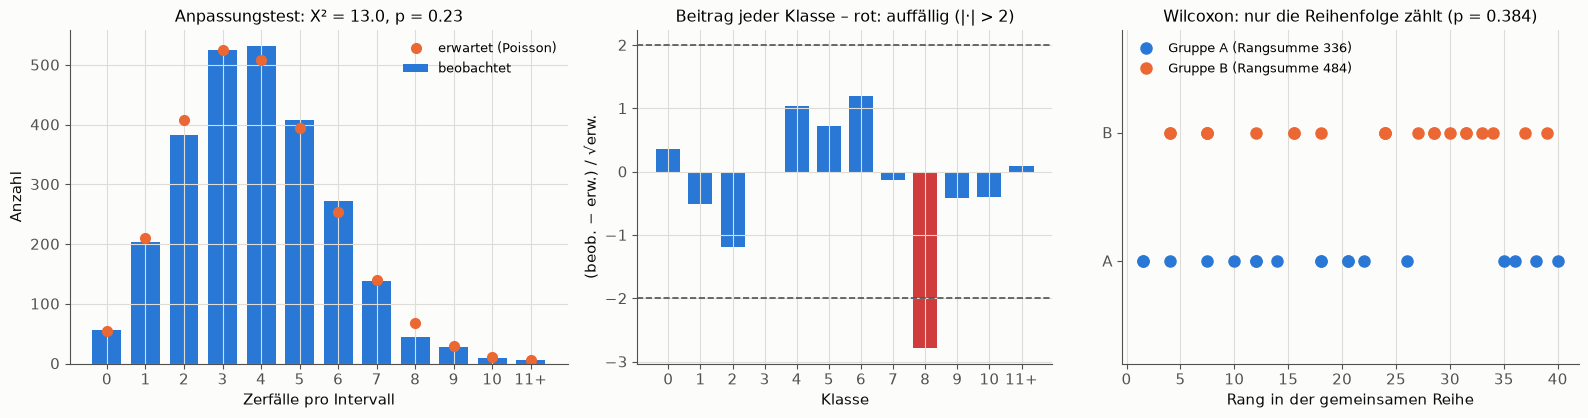

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw={"width_ratios": [1.2, 1, 1.1]})
labels = [str(k) for k in range(11)] + ["11+"]
expected_counts = len(rutherford) * probs

ax = axes[0]
xs = np.arange(12)
ax.bar(xs, observed, color=BLUE, width=0.75, label="beobachtet")
ax.plot(xs, expected_counts, "o", color=ORANGE, label="erwartet (Poisson)")
ax.set_xticks(xs); ax.set_xticklabels(labels)
ax.set_xlabel("Zerfälle pro Intervall"); ax.set_ylabel("Anzahl")
ax.set_title(f"Anpassungstest: X² = {X2_gof:.1f}, p = {X2_gof_p:.2f}"); ax.legend(fontsize=9)

ax = axes[1]
residuals = (observed - expected_counts) / np.sqrt(expected_counts)
ax.bar(xs, residuals, color=[MISS if abs(r) > 2 else BLUE for r in residuals], width=0.75)
for edge in (-2, 2):
    ax.axhline(edge, color=MUTED, ls="--", lw=1.2)
ax.set_xticks(xs); ax.set_xticklabels(labels)
ax.set_xlabel("Klasse"); ax.set_ylabel("(beob. − erw.) / √erw.")
ax.set_title("Beitrag jeder Klasse – rot: auffällig (|·| > 2)")

ax = axes[2]
combined = np.concatenate([group_a, group_b])
ranks = stats.rankdata(combined)
ax.plot(ranks[:len(group_a)], np.zeros(len(group_a)), "o", color=BLUE, ms=8,
        label=f"Gruppe A (Rangsumme {ranks[:len(group_a)].sum():.0f})")
ax.plot(ranks[len(group_a):], np.ones(len(group_b)), "o", color=ORANGE, ms=8,
        label=f"Gruppe B (Rangsumme {ranks[len(group_a):].sum():.0f})")
z, p = wilcoxon_rank_sum_test(group_a, group_b)
ax.set_yticks([0, 1]); ax.set_yticklabels(["A", "B"]); ax.set_ylim(-0.8, 1.8)
ax.set_xlabel("Rang in der gemeinsamen Reihe")
ax.set_title(f"Wilcoxon: nur die Reihenfolge zählt (p = {p:.3f})")
ax.legend(fontsize=9, loc="upper left"); ax.grid(axis="y", visible=False)

plt.tight_layout(); plt.show()

Beide Modellprüfungen kommen zum selben Urteil wie das Skript: Rutherfords Zählwerte sind mit
einer Poisson-Verteilung vereinbar. Die mittlere Grafik zeigt, wo die Abweichungen sitzen:
Bei 8 Zerfällen gibt es deutlich weniger Intervalle als erwartet. Trotzdem verwirft der Test nicht,
und das ist kein Widerspruch: Bei zwölf Klassen ist es nicht ungewöhnlich, dass eine davon zufällig
die Grenze ±2 überschreitet. Der Test bewertet die Summe aller Abweichungen, nicht die größte
(dasselbe Problem vieler Einzelvergleiche zeigt Untersuchung 17).

Rechts der Kern des Wilcoxon-Tests: Er sieht nur die Reihenfolge der Werte. Ein extremer
Ausreißer zählt deshalb nicht mehr als ein knapp größter Wert – der Test ist robust.

---
# Teil II – Das Simulationslabor

Bisher wurde nachgerechnet: Stimmen die inferlab-Formeln? Jetzt wird **nachgezählt**:
Halten die Verfahren in tausendfacher Wiederholung, was die Theorie verspricht?
Die Werkzeuge dafür stehen in `simulate.py`. Jede Untersuchung zieht Daten mit bekannter Wahrheit,
wendet ein Verfahren aus Teil I an und zählt, wie oft es richtig liegt.

## 10. Wird der Schätzer mit mehr Daten besser?

Zwei Fragen an den ML-Schätzer für λ (Rutherford):

- **Wird er genauer, je mehr Daten es gibt?** Seine Streuung sollte wie √(λ/n) fallen.
- **Geht es überhaupt besser?** Die Cramér-Rao-Schranke ist eine untere Grenze für die Streuung
  *jedes* unverzerrten Schätzers. Für Poisson liegt sie bei λ/n. Erreicht der ML-Schätzer sie?

In [25]:
sim_rng = np.random.default_rng(10)
lambda_hat = ml_estimate(rutherford, "poisson")[0]
sizes = [5, 10, 25, 50, 100, 200]

distribution = sim.sampling_distribution(
    sampler=lambda g, n: g.poisson(lambda_hat, n), estimator=np.mean,
    true_value=lambda_hat, sample_sizes=sizes, n_simulations=3000, rng=sim_rng,
)
cramer_rao = sim.cramer_rao_comparison(sizes, lambda_hat, n_simulations=3000, rng=sim_rng)

ratio = cramer_rao["empirical_variance"] / cramer_rao["cramer_rao_bound"]
check_true("Streuung fällt wie √(λ/n) (±10 %)",
           np.allclose(distribution.standard_deviations, np.sqrt(lambda_hat / np.array(sizes)), rtol=0.1),
           "für alle n")
check_true("ML erreicht Cramér-Rao (Verhältnis 0.9–1.1)", np.all(np.abs(ratio - 1) < 0.1),
           ", ".join(f"{r:.2f}" for r in ratio))

✓  Streuung fällt wie √(λ/n) (±10 %)                    für alle n
✓  ML erreicht Cramér-Rao (Verhältnis 0.9–1.1)          0.98, 1.02, 1.04, 0.99, 1.00, 0.98


True

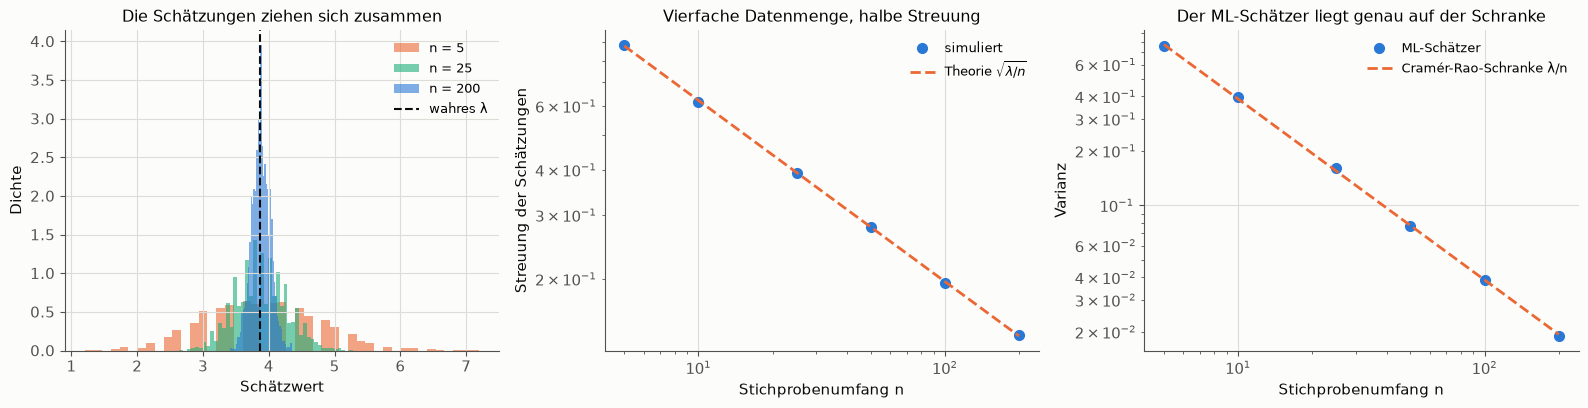

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

ax = axes[0]
for n, color in zip([5, 25, 200], [ORANGE, AQUA, BLUE]):
    ax.hist(distribution.estimates[n], bins=45, density=True, alpha=0.6, color=color, label=f"n = {n}")
ax.axvline(lambda_hat, color=INK, ls="--", lw=1.5, label="wahres λ")
ax.set_xlabel("Schätzwert"); ax.set_ylabel("Dichte")
ax.set_title("Die Schätzungen ziehen sich zusammen"); ax.legend(fontsize=9)

ax = axes[1]
ax.plot(distribution.sample_sizes, distribution.standard_deviations, "o", color=BLUE, label="simuliert")
ax.plot(sizes, np.sqrt(lambda_hat / np.array(sizes)), "--", color=ORANGE, label=r"Theorie $\sqrt{\lambda/n}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Stichprobenumfang n"); ax.set_ylabel("Streuung der Schätzungen")
ax.set_title("Vierfache Datenmenge, halbe Streuung"); ax.legend(fontsize=9)

ax = axes[2]
ax.plot(cramer_rao["sample_sizes"], cramer_rao["empirical_variance"], "o", color=BLUE, label="ML-Schätzer")
ax.plot(cramer_rao["sample_sizes"], cramer_rao["cramer_rao_bound"], "--", color=ORANGE,
        label="Cramér-Rao-Schranke λ/n")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Stichprobenumfang n"); ax.set_ylabel("Varianz")
ax.set_title("Der ML-Schätzer liegt genau auf der Schranke"); ax.legend(fontsize=9)

plt.tight_layout(); plt.show()

Die Punkte rechts liegen auf der Schranke. Der ML-Schätzer ist hier also nicht nur gut,
sondern **bestmöglich**: Kein unverzerrter Schätzer kann weniger streuen.

## 11. Halten 95 %-Intervalle ihr Versprechen?

Ein 95 %-Intervall behauptet: Bei vielen Wiederholungen enthält es den wahren Wert in 95 % der Fälle.
Das lässt sich nachzählen. Spannend wird es, wenn die Annahme „normalverteilt“ verletzt ist:
Exponentialverteilte Daten sind stark schief.

In [27]:
def t_interval(sample, confidence_level):
    return ci_mean_unknown_sigma(mean=np.mean(sample), s=np.std(sample, ddof=1),
                                 n=len(sample), confidence_level=confidence_level)

sim_rng = np.random.default_rng(11)
single_run = sim.coverage_probability(
    sampler=lambda g, n: g.normal(100, 15, n), interval_fn=t_interval,
    true_value=100.0, n=20, n_simulations=3000, rng=sim_rng,
)
coverage_sizes = [5, 10, 20, 50, 100]
normal_coverage = sim.coverage_across_sample_sizes(
    lambda g, n: g.normal(100, 15, n), t_interval, 100.0, coverage_sizes, 2000, sim_rng)
skewed_coverage = sim.coverage_across_sample_sizes(
    lambda g, n: g.exponential(2.0, n), t_interval, 2.0, coverage_sizes, 2000, sim_rng)

check("Normale Daten, n = 20: Überdeckung ≈ 95 % (±1.5 %)", single_run.coverage, 0.95, rel=0, abs_=0.015)
check_true("Schiefe Daten, n = 5: deutlich unter 95 %", skewed_coverage["coverage"][0] < 0.92,
           f"{skewed_coverage['coverage'][0]:.1%}")

✓  Normale Daten, n = 20: Überdeckung ≈ 95 % (±1.5 %)   ours 0.947                      ref 0.95
✓  Schiefe Daten, n = 5: deutlich unter 95 %            88.2%


True

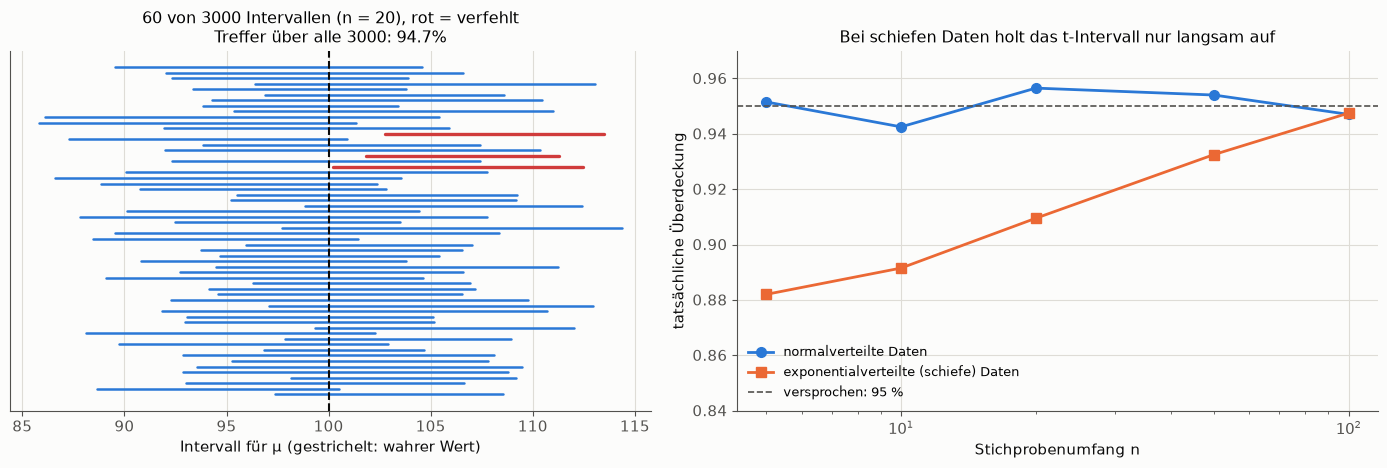

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

ax = axes[0]
for i in range(60):
    hit = single_run.covers[i]
    ax.plot([single_run.lower[i], single_run.upper[i]], [i, i], color=BLUE if hit else MISS,
            lw=1.8 if hit else 2.4, solid_capstyle="round")
ax.axvline(single_run.true_value, color=INK, ls="--", lw=1.5)
ax.set_yticks([]); ax.set_xlabel("Intervall für μ (gestrichelt: wahrer Wert)")
ax.set_title(f"60 von 3000 Intervallen (n = 20), rot = verfehlt\nTreffer über alle 3000: {single_run.coverage:.1%}")

ax = axes[1]
ax.plot(normal_coverage["sample_sizes"], normal_coverage["coverage"], "o-", color=BLUE,
        label="normalverteilte Daten")
ax.plot(skewed_coverage["sample_sizes"], skewed_coverage["coverage"], "s-", color=ORANGE,
        label="exponentialverteilte (schiefe) Daten")
ax.axhline(0.95, color=MUTED, ls="--", lw=1.2, label="versprochen: 95 %")
ax.set_xscale("log"); ax.set_ylim(0.84, 0.97)
ax.set_xlabel("Stichprobenumfang n"); ax.set_ylabel("tatsächliche Überdeckung")
ax.set_title("Bei schiefen Daten holt das t-Intervall nur langsam auf"); ax.legend(fontsize=9)

plt.tight_layout(); plt.show()

Bei normalen Daten stimmen die 95 % schon ab n = 5. Bei schiefen Daten ist das Intervall
anfangs zu schmal – man ist zu selbstsicher – und erreicht die 95 % erst bei 50 bis 100 Beobachtungen.
Das ist der zentrale Grenzwertsatz bei der Arbeit (mehr dazu in Untersuchung 14).

## 12. Wie oft findet ein Test einen echten Effekt?

Ein Test kann auf zwei Arten danebenliegen: Er schlägt Alarm, obwohl nichts ist (Fehler 1. Art,
begrenzt durch α), oder er übersieht einen echten Effekt (Fehler 2. Art). Die **Güte** ist die
Wahrscheinlichkeit, einen vorhandenen Effekt zu finden. Für den t-Test gibt es dafür eine exakte
Formel – die Simulation muss sie treffen.

In [29]:
sim_rng = np.random.default_rng(12)
effect_sizes = np.linspace(0, 1.5, 16)
curve = sim.power_curve(effect_sizes, n=20, n_simulations=4000, rng=sim_rng)
by_size = {k: sim.power_curve(effect_sizes, n=k, n_simulations=2000, rng=sim_rng) for k in [10, 20, 50]}
needed_n = sim.power_across_sample_sizes(effect_size=0.5, sample_sizes=[5, 10, 20, 30, 40, 50, 80, 120],
                                         n_simulations=3000, rng=sim_rng)

check("Güte: Simulation gegen exakte Formel (±0.025)", curve.power, curve.theoretical_power,
      rel=0, abs_=0.025)
check("Ohne Effekt: Ablehnrate = α (±0.01)", curve.power[0], 0.05, rel=0, abs_=0.01)

✓  Güte: Simulation gegen exakte Formel (±0.025)        ours 0.0515, 0.06775, 0.13075, 0.2455, 0.3935, 0.5635, 0.72175, 0.843, 0.923, 0.96925, 0.98775, 0.997, 0.99925, 1, 1, 1 ref 0.05, 0.0709412, 0.135956, 0.247089, 0.396994, 0.564504, 0.721005, 0.843506, 0.923899, 0.968152, 0.988591, 0.996516, 0.999095, 0.999801, 0.999963, 0.999994
✓  Ohne Effekt: Ablehnrate = α (±0.01)                  ours 0.0515                     ref 0.05


True

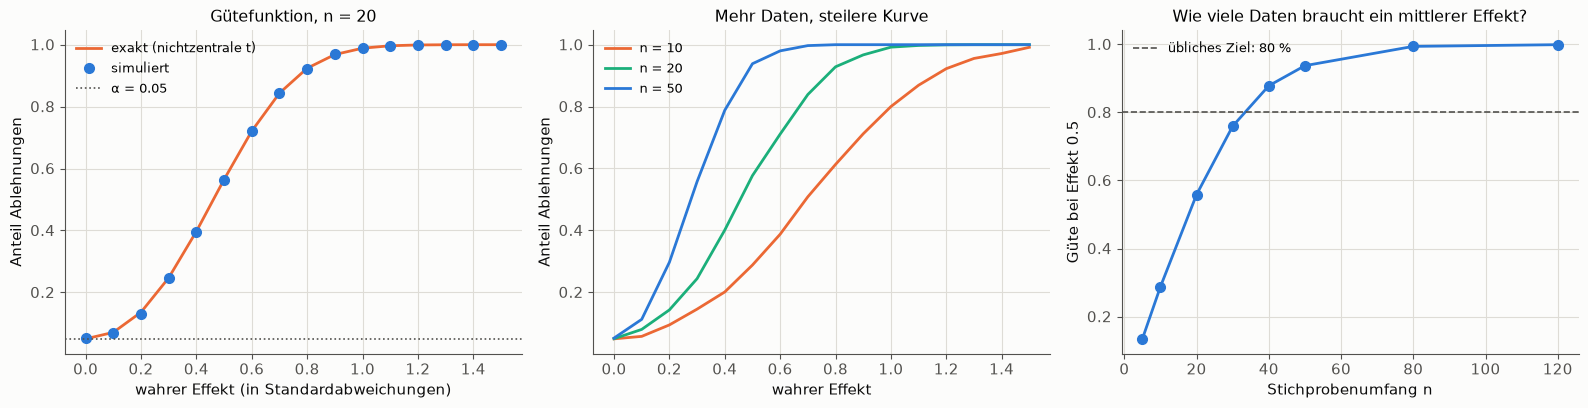

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

ax = axes[0]
ax.plot(curve.effect_sizes, curve.theoretical_power, color=ORANGE, label="exakt (nichtzentrale t)")
ax.plot(curve.effect_sizes, curve.power, "o", color=BLUE, label="simuliert")
ax.axhline(0.05, color=MUTED, ls=":", lw=1.2, label="α = 0.05")
ax.set_xlabel("wahrer Effekt (in Standardabweichungen)"); ax.set_ylabel("Anteil Ablehnungen")
ax.set_title("Gütefunktion, n = 20"); ax.legend(fontsize=9)

ax = axes[1]
for (k, result), color in zip(by_size.items(), [ORANGE, AQUA, BLUE]):
    ax.plot(result.effect_sizes, result.power, color=color, label=f"n = {k}")
ax.set_xlabel("wahrer Effekt"); ax.set_ylabel("Anteil Ablehnungen")
ax.set_title("Mehr Daten, steilere Kurve"); ax.legend(fontsize=9)

ax = axes[2]
ax.plot(needed_n["sample_sizes"], needed_n["power"], "o-", color=BLUE)
ax.axhline(0.8, color=MUTED, ls="--", lw=1.2, label="übliches Ziel: 80 %")
ax.set_xlabel("Stichprobenumfang n"); ax.set_ylabel("Güte bei Effekt 0.5")
ax.set_title("Wie viele Daten braucht ein mittlerer Effekt?"); ax.legend(fontsize=9)

plt.tight_layout(); plt.show()

Die Simulation liegt auf der exakten Kurve. Praktisch wichtig ist die rechte Grafik: Für einen
mittleren Effekt braucht man 30 bis 40 Beobachtungen, um ihn in 80 % der Fälle zu finden
(die exakte Formel sagt 34).
Mit n = 10 findet man ihn nur etwa in einem Viertel der Fälle. Ein solches Experiment zeigt
meistens nichts, obwohl etwas da ist.

## 13. Was passiert, wenn die Annahmen nicht stimmen?

Die Tests aus Kapitel 4 setzen normalverteilte Daten voraus. Hier werden Daten erzeugt, für die
H₀ **wahr** ist – jede Ablehnung ist also ein Fehlalarm. Ein verlässlicher Test schlägt in 5 % der
Fälle Alarm. Was passiert mit schiefen Daten?

In [31]:
def variance_test_p(sample):
    return variance_test(s=np.std(sample, ddof=1), sigma0=2.0, n=len(sample))[1]

def t_test_p(sample):
    return t_test(mean=np.mean(sample), mu0=2.0, s=np.std(sample, ddof=1), n=len(sample))[1]

scenarios = {
    "Varianztest / normal":      (lambda g, n: g.normal(2.0, 2.0, n), variance_test_p),
    "Varianztest / exponential": (lambda g, n: g.exponential(2.0, n), variance_test_p),
    "t-Test / normal":           (lambda g, n: g.normal(2.0, 2.0, n), t_test_p),
    "t-Test / exponential":      (lambda g, n: g.exponential(2.0, n), t_test_p),
}
sim_rng = np.random.default_rng(13)
robustness = sim.robustness_comparison(scenarios, n=30, n_simulations=4000, rng=sim_rng)

rates = {r.label: r.rejection_rate for r in robustness}
check_true("Varianztest bricht bei schiefen Daten ein (> 20 %)", rates["Varianztest / exponential"] > 0.2,
           f"{rates['Varianztest / exponential']:.1%}")
check_true("t-Test bleibt in der Nähe von 5 % (< 9 %)", rates["t-Test / exponential"] < 0.09,
           f"{rates['t-Test / exponential']:.1%}")

✓  Varianztest bricht bei schiefen Daten ein (> 20 %)   29.8%
✓  t-Test bleibt in der Nähe von 5 % (< 9 %)            6.9%


True

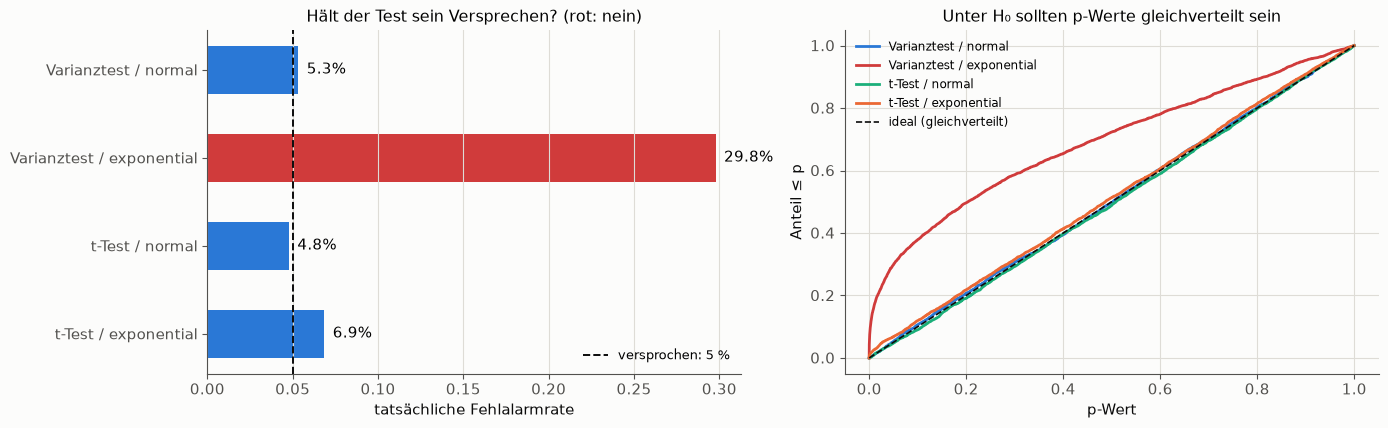

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))

ax = axes[0]
labels = [r.label for r in robustness]
values = [r.rejection_rate for r in robustness]
bars = ax.barh(labels, values, color=[MISS if v > 0.075 else BLUE for v in values], height=0.55)
ax.axvline(0.05, color=INK, ls="--", lw=1.4, label="versprochen: 5 %")
for bar, v in zip(bars, values):
    ax.text(v + 0.005, bar.get_y() + bar.get_height() / 2, f"{v:.1%}", va="center")
ax.invert_yaxis(); ax.set_xlabel("tatsächliche Fehlalarmrate")
ax.set_title("Hält der Test sein Versprechen? (rot: nein)"); ax.legend(fontsize=9, loc="lower right")
ax.grid(axis="y", visible=False)

ax = axes[1]
for r, color in zip(robustness, [BLUE, MISS, AQUA, ORANGE]):
    ax.plot(np.sort(r.p_values), np.linspace(0, 1, len(r.p_values)), color=color, label=r.label)
ax.plot([0, 1], [0, 1], color=INK, ls="--", lw=1.2, label="ideal (gleichverteilt)")
ax.set_xlabel("p-Wert"); ax.set_ylabel("Anteil ≤ p")
ax.set_title("Unter H₀ sollten p-Werte gleichverteilt sein"); ax.legend(fontsize=8.5)

plt.tight_layout(); plt.show()

Das deutlichste Ergebnis des Labors: Der **χ²-Varianztest schlägt bei schiefen Daten in fast
30 % der Fälle Alarm** statt in 5 %. Der t-Test bleibt bei denselben Daten nahe am
versprochenen Wert. Der Grund: Für den *Mittelwert* greift der zentrale Grenzwertsatz,
für die *Streuung* gibt es kein solches Rettungsnetz.

## 14. Grenzwertsätze als Bild

- **Zentraler Grenzwertsatz:** Mittelwerte werden mit wachsendem n normalverteilt – egal, wie schief die Ausgangsdaten sind.
- **Gesetz der großen Zahlen:** Der laufende Mittelwert läuft auf den Erwartungswert zu.

Ausgangspunkt ist die stark schiefe Exponentialverteilung.

In [33]:
sim_rng = np.random.default_rng(14)
clt = sim.central_limit_demo(sampler=lambda g, n: g.exponential(1.0, n),
                             sample_sizes=[1, 2, 5, 30], n_simulations=4000, rng=sim_rng)
lln = sim.law_of_large_numbers_paths(sampler=lambda g, n: g.exponential(2.0, n),
                                     true_value=2.0, max_n=400, n_paths=12, rng=sim_rng)
skews = {k: stats.skew(v) for k, v in clt.items()}
check_true("Schiefe schrumpft mit n", skews[1] > skews[5] > skews[30],
           ", ".join(f"n={k}: {v:.2f}" for k, v in skews.items()))

✓  Schiefe schrumpft mit n                              n=1: 1.82, n=2: 1.38, n=5: 0.94, n=30: 0.35


True

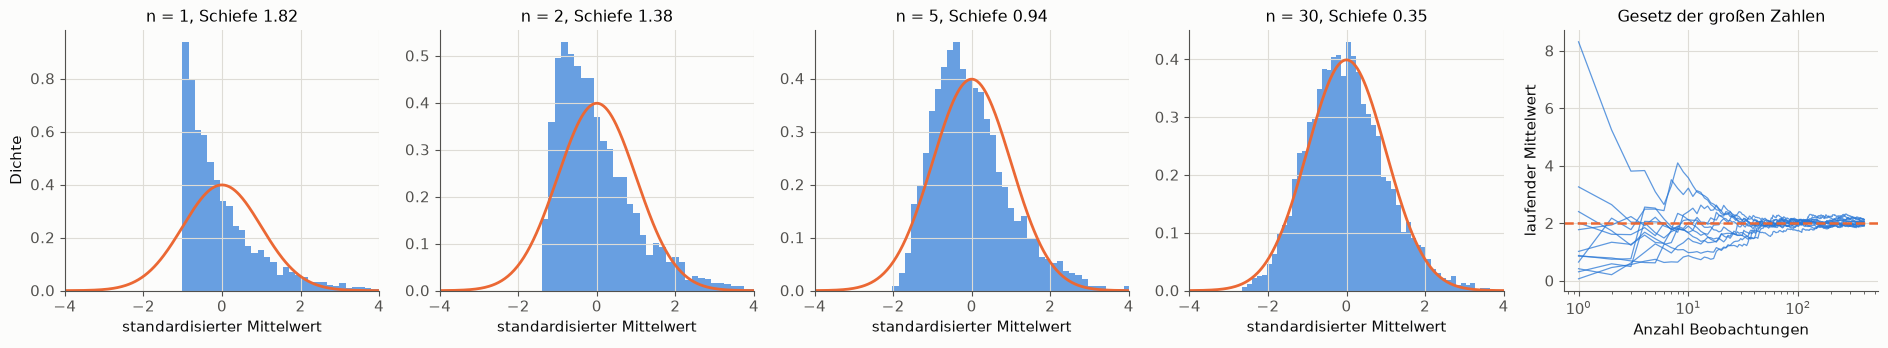

In [34]:
fig, axes = plt.subplots(1, 5, figsize=(19, 3.6))
grid = np.linspace(-4, 4, 300)
for ax, (k, values) in zip(axes[:4], clt.items()):
    ax.hist(values, bins=50, density=True, color=BLUE, alpha=0.7)
    ax.plot(grid, stats.norm.pdf(grid), color=ORANGE)
    ax.set_xlim(-4, 4); ax.set_xlabel("standardisierter Mittelwert")
    ax.set_title(f"n = {k}, Schiefe {skews[k]:.2f}")
axes[0].set_ylabel("Dichte")

ax = axes[4]
for path in lln.paths:
    ax.plot(lln.sample_sizes, path, lw=0.9, alpha=0.75, color=BLUE)
ax.axhline(lln.true_value, color=ORANGE, ls="--", lw=1.8)
ax.set_xscale("log"); ax.set_xlabel("Anzahl Beobachtungen"); ax.set_ylabel("laufender Mittelwert")
ax.set_title("Gesetz der großen Zahlen")

plt.tight_layout(); plt.show()

Bei n = 1 sieht man die schiefe Ausgangsverteilung (Schiefe fast 2). Bei n = 30 schmiegt sich das
Histogramm fast an die Normalkurve. Rechts laufen zwölf Pfade trichterförmig auf den
Erwartungswert zu: Die Konvergenz ist sicher, aber nicht schnell.

## 15. Bootstrap gegen klassisch

Untersuchung 11 hat gezeigt: Das t-Intervall verfehlt bei schiefen Daten und kleinem n seine 95 %.
Kann der Bootstrap das besser? Verglichen werden drei Intervalle auf exponentialverteilten Daten:
das klassische t-Intervall und beide Bootstrap-Varianten.

*Diese Zelle rechnet etwa eine halbe Minute, weil für jede Wiederholung ein kompletter Bootstrap läuft.*

In [35]:
sim_rng = np.random.default_rng(15)
boot_sizes = [5, 10, 20, 50]
comparison = sim.bootstrap_vs_classical_coverage(
    sampler=lambda g, n: g.exponential(2.0, n), true_value=2.0, sample_sizes=boot_sizes,
    n_simulations=500, rng=sim_rng,
    bootstrap_ci_fn=lambda smp, cl: bootstrap_percentile_ci(smp, np.mean, 500, cl, sim_rng),
    classical_ci_fn=t_interval,
)
# Bei n = 5 kann eine Bootstrap-Stichprobe aus lauter gleichen Werten bestehen. Dann ist ihre
# Streuung 0 und Bootstrap-t teilt durch 0. Die Warnung wird hier bewusst unterdrückt (siehe Text).
with np.errstate(divide="ignore", invalid="ignore"):
    boot_t = sim.coverage_across_sample_sizes(
        sampler=lambda g, n: g.exponential(2.0, n),
        interval_fn=lambda smp, cl: bootstrap_t_ci_mean(smp, 500, cl, sim_rng),
        true_value=2.0, sample_sizes=boot_sizes, n_simulations=500, rng=sim_rng,
    )
check_true("Bootstrap-t schlägt Perzentil bei n = 10",
           boot_t["coverage"][1] > comparison["bootstrap_coverage"][1],
           f"{boot_t['coverage'][1]:.1%} gegen {comparison['bootstrap_coverage'][1]:.1%}")

✓  Bootstrap-t schlägt Perzentil bei n = 10             93.4% gegen 85.6%


True

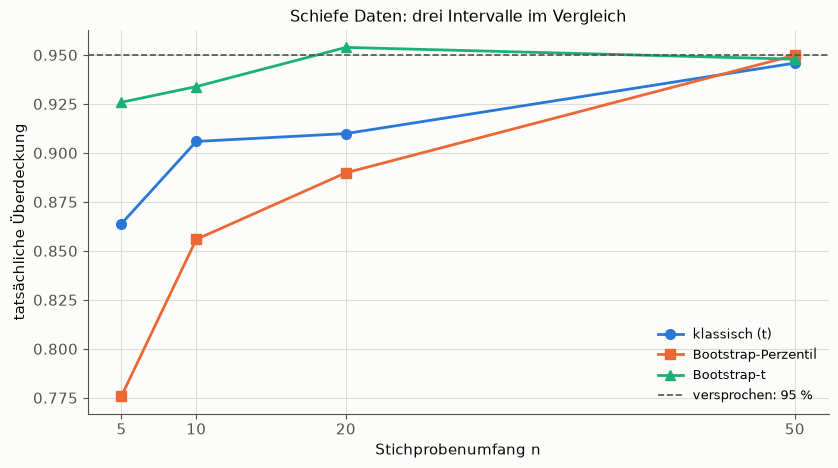

  n =  5:  klassisch 0.864   Perzentil 0.776   Bootstrap-t 0.926
  n = 10:  klassisch 0.906   Perzentil 0.856   Bootstrap-t 0.934
  n = 20:  klassisch 0.910   Perzentil 0.890   Bootstrap-t 0.954
  n = 50:  klassisch 0.946   Perzentil 0.950   Bootstrap-t 0.948


In [36]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(boot_sizes, comparison["classical_coverage"], "o-", color=BLUE, label="klassisch (t)")
ax.plot(boot_sizes, comparison["bootstrap_coverage"], "s-", color=ORANGE, label="Bootstrap-Perzentil")
ax.plot(boot_sizes, boot_t["coverage"], "^-", color=AQUA, label="Bootstrap-t")
ax.axhline(0.95, color=MUTED, ls="--", lw=1.2, label="versprochen: 95 %")
ax.set_xticks(boot_sizes)
ax.set_xlabel("Stichprobenumfang n"); ax.set_ylabel("tatsächliche Überdeckung")
ax.set_title("Schiefe Daten: drei Intervalle im Vergleich"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

for k, c, b, bt in zip(boot_sizes, comparison["classical_coverage"],
                       comparison["bootstrap_coverage"], boot_t["coverage"]):
    print(f"  n = {k:2d}:  klassisch {c:.3f}   Perzentil {b:.3f}   Bootstrap-t {bt:.3f}")

Ein lehrreiches Ergebnis: Der **Perzentil-Bootstrap ist bei kleinem n schlechter** als das klassische
Intervall, nicht besser. Er korrigiert die Schiefe nicht. Genau dafür ist das **Bootstrap-t** gedacht:
Es teilt jede Bootstrap-Abweichung durch ihre eigene Streuung und kommt der 95 % am nächsten.

Die allgemeine Lehre: Weniger Annahmen heißt nicht automatisch besser. Auch der Bootstrap braucht
genug Daten, um die Wirklichkeit nachzubilden.

**Nebenbefund:** Bei n = 5 stößt `bootstrap_t_ci_mean` an einen Randfall. Besteht eine
Bootstrap-Stichprobe zufällig nur aus gleichen Werten, ist ihre Streuung 0, und es wird durch 0
geteilt. Das Ergebnis bleibt hier brauchbar, weil solche Fälle in den äußersten Prozenten landen
und für die Intervallgrenzen keine Rolle spielen. Robuster wäre es, solche Stichproben zu überspringen.

## 16. Ungleiche Streuungen: Welch gegen gepoolt

Der klassische Zwei-Stichproben-t-Test aus Kapitel 5 nimmt an, dass beide Gruppen gleich stark
streuen. Was, wenn nicht? Besonders heikel ist der Fall, dass die **kleine Gruppe stark streut**.
Beide Gruppen haben hier denselben Mittelwert – jede Ablehnung ist ein Fehlalarm.

In [37]:
N_SMALL, N_LARGE = 10, 40

def two_groups(sd_small):
    # liefert beide Gruppen hintereinander; der Test trennt sie wieder
    return lambda g, n: np.r_[g.normal(0, sd_small, N_SMALL), g.normal(0, 1, N_LARGE)]

def split(sample):
    a, b = sample[:N_SMALL], sample[N_SMALL:]
    return dict(mean1=a.mean(), s1=a.std(ddof=1), n1=len(a), mean2=b.mean(), s2=b.std(ddof=1), n2=len(b))

pooled_p = lambda smp: two_sample_t_test(**split(smp))[1]
welch_p = lambda smp: welch_test(**split(smp))[1]

sim_rng = np.random.default_rng(16)
ratios = [0.5, 1, 1.5, 2, 3, 4]
pooled_rates, welch_rates = [], []
for sd in ratios:
    result = sim.robustness_comparison({"gepoolt": (two_groups(sd), pooled_p),
                                        "Welch": (two_groups(sd), welch_p)},
                                       n=N_SMALL + N_LARGE, n_simulations=3000, rng=sim_rng)
    pooled_rates.append(result[0].rejection_rate); welch_rates.append(result[1].rejection_rate)

check_true("Welch hält 5 % über alle Verhältnisse (< 7 %)", max(welch_rates) < 0.07,
           f"max {max(welch_rates):.1%}")
check_true("Gepoolter Test bricht ein (> 15 % bei Faktor 4)", pooled_rates[-1] > 0.15,
           f"{pooled_rates[-1]:.1%}")

✓  Welch hält 5 % über alle Verhältnisse (< 7 %)        max 5.5%
✓  Gepoolter Test bricht ein (> 15 % bei Faktor 4)      30.1%


True

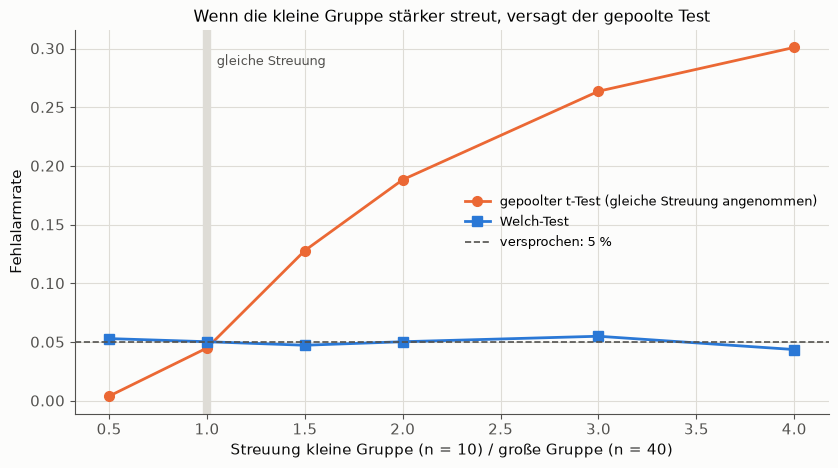

In [38]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(ratios, pooled_rates, "o-", color=ORANGE, label="gepoolter t-Test (gleiche Streuung angenommen)")
ax.plot(ratios, welch_rates, "s-", color=BLUE, label="Welch-Test")
ax.axhline(0.05, color=MUTED, ls="--", lw=1.2, label="versprochen: 5 %")
ax.axvline(1, color=GRID, lw=6, zorder=0)
ax.text(1.05, max(pooled_rates) * 0.95, "gleiche Streuung", color=MUTED, fontsize=9)
ax.set_xlabel(f"Streuung kleine Gruppe (n = {N_SMALL}) / große Gruppe (n = {N_LARGE})")
ax.set_ylabel("Fehlalarmrate")
ax.set_title("Wenn die kleine Gruppe stärker streut, versagt der gepoolte Test")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

Solange die Streuungen gleich sind (Faktor 1), sind beide Tests gleich gut. Streut die kleine
Gruppe stärker, unterschätzt der gepoolte Test die Unsicherheit und schlägt viel zu oft Alarm.
Streut die kleine Gruppe schwächer (Faktor 0.5), wird er übervorsichtig. Welch bleibt in allen
Fällen bei 5 %. Deshalb ist Welch in vielen Programmen inzwischen die Voreinstellung.

## 17. Viele Vergleiche, viele Fehlalarme

Kapitel 6 hat Korrekturen für Paarvergleiche benutzt. Wie nötig sind sie? Hier haben **alle
Gruppen denselben Mittelwert**. Gezählt wird, wie oft *mindestens ein* Paarvergleich trotzdem
Alarm schlägt – ohne Korrektur, mit Bonferroni und mit Tukey.

*Diese Zelle rechnet etwa eine Minute, weil Tukeys Verteilung aufwendig auszuwerten ist.*

In [39]:
PER_GROUP = 10

def equal_groups(k):
    return lambda g, n: g.normal(0, 1, k * PER_GROUP)

def as_groups(sample):
    return list(sample.reshape(-1, PER_GROUP))

def raw_min_p(sample):
    gs = as_groups(sample); smallest = 1.0
    for i in range(len(gs)):
        for j in range(i + 1, len(gs)):
            p = two_sample_t_test(gs[i].mean(), gs[i].std(ddof=1), PER_GROUP,
                                  gs[j].mean(), gs[j].std(ddof=1), PER_GROUP)[1]
            smallest = min(smallest, p)
    return smallest

bonferroni_min_p = lambda smp: min(c.p_value for c in bonferroni_pairwise(as_groups(smp)))
tukey_min_p = lambda smp: min(c.p_value for c in tukey_hsd(as_groups(smp)))

sim_rng = np.random.default_rng(17)
group_counts = [2, 3, 4, 5, 6]
family_rates = {"ohne Korrektur": [], "Bonferroni": [], "Tukey": []}
for k in group_counts:
    result = sim.robustness_comparison(
        {"ohne Korrektur": (equal_groups(k), raw_min_p),
         "Bonferroni": (equal_groups(k), bonferroni_min_p),
         "Tukey": (equal_groups(k), tukey_min_p)},
        n=k * PER_GROUP, n_simulations=400, rng=sim_rng)
    for r in result:
        family_rates[r.label].append(r.rejection_rate)

check_true("Ohne Korrektur: bei 6 Gruppen > 25 % Fehlalarme", family_rates["ohne Korrektur"][-1] > 0.25,
           f"{family_rates['ohne Korrektur'][-1]:.1%}")
check_true("Tukey bleibt nahe 5 % (< 9 %)", max(family_rates["Tukey"]) < 0.09,
           f"max {max(family_rates['Tukey']):.1%}")

✓  Ohne Korrektur: bei 6 Gruppen > 25 % Fehlalarme      35.0%
✓  Tukey bleibt nahe 5 % (< 9 %)                        max 5.5%


True

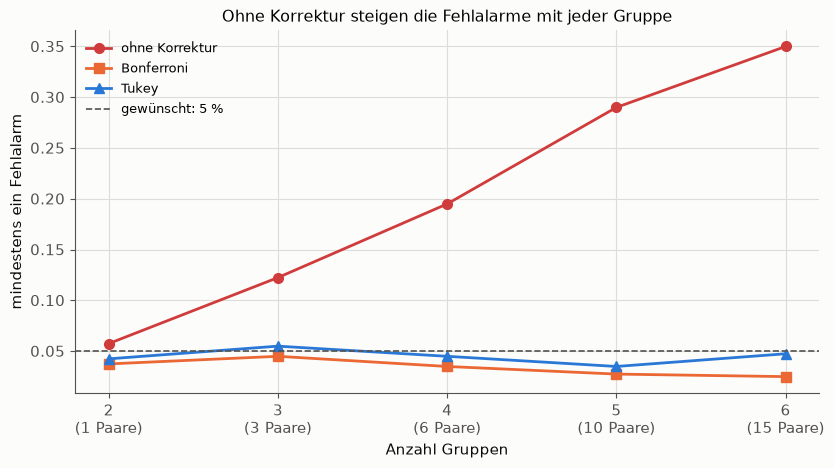

In [40]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for (label, values), color, marker in zip(family_rates.items(), [MISS, ORANGE, BLUE], ["o", "s", "^"]):
    ax.plot(group_counts, values, marker=marker, color=color, label=label)
ax.axhline(0.05, color=MUTED, ls="--", lw=1.2, label="gewünscht: 5 %")
pairs = [k * (k - 1) // 2 for k in group_counts]
ax.set_xticks(group_counts)
ax.set_xticklabels([f"{k}\n({p} Paare)" for k, p in zip(group_counts, pairs)])
ax.set_xlabel("Anzahl Gruppen"); ax.set_ylabel("mindestens ein Fehlalarm")
ax.set_title("Ohne Korrektur steigen die Fehlalarme mit jeder Gruppe"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

Bei zwei Gruppen gibt es nur einen Vergleich, alle drei Linien starten bei 5 %. Mit sechs Gruppen
und 15 Paaren meldet der unkorrigierte Ansatz in mehr als jedem dritten Experiment einen Unterschied,
der nicht existiert, und die Kurve steigt weiter. Bonferroni hält die Rate zuverlässig bei oder
unter 5 %, ist aber eher übervorsichtig. Tukey trifft die 5 % – er ist für genau diese Situation gebaut.

---
## Zum Schluss: Prüfprotokoll

Alle Prüfungen dieses Notebooks auf einen Blick. Ein einziges ✗ heißt: Irgendwo in `inferlab`
stimmt etwas nicht, und die Zeile nennt die Stelle.

In [41]:
passed = sum(ok for _, ok, _, _ in protocol)
rows = "\n".join(f"| {'✓' if ok else '✗'} | {label} | {ours} | {ref} |" for label, ok, ours, ref in protocol)
display(Markdown(f"**{passed} von {len(protocol)} Prüfungen bestanden.**\n\n"
                 "| | Prüfung | inferlab | Referenz |\n|---|---|---|---|\n" + rows))
assert passed == len(protocol), "Mindestens eine Prüfung ist fehlgeschlagen."

**82 von 82 Prüfungen bestanden.**

| | Prüfung | inferlab | Referenz |
|---|---|---|---|
| ✓ | Rutherford: Anzahl Intervalle | 2608 | 2608 |
| ✓ | Rutherford: Mittelwert (Skript 3.87) | 3.87 | 3.87 |
| ✓ | Notaufnahme: Mittelwert (32.9 min) | 32.9 | 32.9 |
| ✓ | PTCA: Gesamtzahl Patienten | 131 | 131 |
| ✓ | ML  Poisson – Rutherford | 3.87155 | 3.87155 |
| ✓ | Mom Poisson – Rutherford | 3.87155 | 3.87155 |
| ✓ | ML  Exponential – Notaufnahme | 0.0303951 | 0.0303951 |
| ✓ | Mom Exponential – Notaufnahme | 0.0303951 | 0.0303951 |
| ✓ | ML  Normal – IQ-Stichprobe | 100.329, 14.7022 | 100.329, 14.7022 |
| ✓ | Mom Normal – IQ-Stichprobe | 100.329, 14.7022 | 100.329, 14.7022 |
| ✓ | ML  Geometrisch – simuliert | 0.325521 | 0.325521 |
| ✓ | Mom Geometrisch – simuliert | 0.325521 | 0.325521 |
| ✓ | Beta-Binomial, flach: Beta(1, 1) | 0.363636 | 0.363636 |
| ✓ | Beta-Binomial, skeptisch: Beta(10, 10) | 0.425 | 0.425 |
| ✓ | Normal-Normal gegen Präzisionsformel | 109.22 | 109.22 |
| ✓ | Normal-Normal: sehr vages Vorwissen → x̄ | 109.634 | 109.634 |
| ✓ | Normal-Normal: sehr festes Vorwissen → ν | 100 | 100 |
| ✓ | z-Intervall gegen scipy | 93.3878, 105.148 | 93.3878, 105.148 |
| ✓ | t-Intervall gegen scipy | 91.9525, 106.583 | 91.9525, 106.583 |
| ✓ | Varianz-Intervall gegen χ²-Quantile | 191.482, 607.806 | 191.482, 607.806 |
| ✓ | Bootstrap-Perzentil gegen scipy (Zufall: ±1) | 92.5578, 106.472 | 92.5474, 106.261 |
| ✓ | Bootstrap-t nahe am t-Intervall (±1.5) | 92.8426, 107.568 | 91.9525, 106.583 |
| ✓ | t-Test gegen scipy: Statistik | -0.206603 | -0.206603 |
| ✓ | t-Test gegen scipy: p-Wert | 0.838063 | 0.838063 |
| ✓ | Gauß-Test, Alternative two_sided | 0.80716 | 0.80716 |
| ✓ | Gauß-Test, Alternative greater | 0.59642 | 0.59642 |
| ✓ | Gauß-Test, Alternative less | 0.40358 | 0.40358 |
| ✓ | t-Test ↔ t-Intervall: 301 Testwerte | Entscheidung immer gleich | Eigenschaft |
| ✓ | Varianztest ↔ Varianz-Intervall: 221 Testwerte | Entscheidung immer gleich | Eigenschaft |
| ✓ | p-Wert am Intervallrand = 0.05 | 0.05 | 0.05 |
| ✓ | LQ-Test Poisson gegen geschlossene Formel | 10.8748 | 10.8748 |
| ✓ | Reaktionszeiten: T (Skript 2.63) | 2.62764 | 2.63 |
| ✓ | Reaktionszeiten: p (Skript 0.0108) | 0.0108221 | 0.0108 |
| ✓ | 2-Stichproben-t gegen scipy | 2.62764, 0.0108221 | 2.62764, 0.0108221 |
| ✓ | Welch-Test gegen scipy | 2.62764, 0.0110414 | 2.62764, 0.0110414 |
| ✓ | F-Test gegen F-Verteilung | 1.88274, 0.0830684 | 1.88274, 0.0830684 |
| ✓ | Gepaarter t-Test gegen scipy | 10.1337, 7.92216e-08 | 10.1337, 7.92216e-08 |
| ✓ | ANOVA gegen scipy | 8.64923, 0.000167779 | 8.64923, 0.000167779 |
| ✓ | Tukey gegen scipy (alle 6 Paare) | 0.999959, 0.00176153, 0.97248, 0.0011886, 0.959072, 0.000664709 | 0.999959, 0.00176153, 0.97248, 0.0011886, 0.959072, 0.000664709 |
| ✓ | Bonferroni gegen scipy-t-Tests × 6 | 1, 0.00753491, 1, 0.0019921, 1, 0.000930821 | 1, 0.00753491, 1, 0.0019921, 1, 0.000930821 |
| ✓ | Zwei Gruppen: ANOVA-F = t² | 0.00200008 | 0.00200008 |
| ✓ | Achsenabschnitt, Steigung gegen scipy | 25.1908, 3.01192 | 25.1908, 3.01192 |
| ✓ | Standardfehler gegen scipy | 1.91575, 0.172345 | 1.91575, 0.172345 |
| ✓ | p-Wert der Steigung gegen scipy | 9.3038e-20 | 9.3038e-20 |
| ✓ | R² gegen scipy | 0.889346 | 0.889346 |
| ✓ | Einfache Regression: F = t² | 305.414 | 305.414 |
| ✓ | Mittelwert-Intervall bei x = 10 gegen statsmodels | 53.2398, 57.3801 | 53.2398, 57.3801 |
| ✓ | Prognose-Intervall bei x = 10 gegen statsmodels | 42.117, 68.503 | 42.117, 68.503 |
| ✓ | Zwei Einflussgrößen gegen numpy lstsq | 8.76234, 2.58721, 3.79973 | 8.76234, 2.58721, 3.79973 |
| ✓ | PTCA: X² (Referenz 8.1767) | 8.17667 | 8.1767 |
| ✓ | PTCA: Fisher p (Referenz 0.005824) | 0.00582363 | 0.005824 |
| ✓ | χ²-Test gegen scipy | 8.17667, 0.00424325 | 8.17667, 0.00424325 |
| ✓ | Fisher gegen scipy | 0.00582363 | 0.00582363 |
| ✓ | Fisher einseitig (greater) gegen scipy | 0.998895 | 0.998895 |
| ✓ | Fisher einseitig (less) gegen scipy | 0.00516101 | 0.00516101 |
| ✓ | Wald-Statistik (Skript −2.9) | -2.9 | -2.9 |
| ✓ | Wald-Statistik² = X² | 8.17667 | 8.17667 |
| ✓ | Rutherford: D (Skript 2489) | 2488.92 | 2489 |
| ✓ | Rutherford: Poisson wird nicht verworfen | p = 0.099 | Eigenschaft |
| ✓ | Rutherford: X² (Skript 13.0) | 12.9613 | 13 |
| ✓ | Anpassungstest gegen scipy | 12.9613, 0.225844 | 12.9613, 0.225844 |
| ✓ | Arbuthnot: p = (1/2)^82 | 2.06795e-25 | 2.06795e-25 |
| ✓ | Vorzeichentest Notaufnahme, m0 = 20 | 0.753906 | 0.753906 |
| ✓ | Vorzeichentest Notaufnahme, m0 = 30 | 0.753906 | 0.753906 |
| ✓ | Vorzeichentest Notaufnahme, m0 = 45 | 0.34375 | 0.34375 |
| ✓ | Wilcoxon (two_sided) gegen scipy | 0.383628 | 0.383628 |
| ✓ | Wilcoxon (greater) gegen scipy | 0.815529 | 0.815529 |
| ✓ | Wilcoxon (less) gegen scipy | 0.191814 | 0.191814 |
| ✓ | Streuung fällt wie √(λ/n) (±10 %) | für alle n | Eigenschaft |
| ✓ | ML erreicht Cramér-Rao (Verhältnis 0.9–1.1) | 0.98, 1.02, 1.04, 0.99, 1.00, 0.98 | Eigenschaft |
| ✓ | Normale Daten, n = 20: Überdeckung ≈ 95 % (±1.5 %) | 0.947 | 0.95 |
| ✓ | Schiefe Daten, n = 5: deutlich unter 95 % | 88.2% | Eigenschaft |
| ✓ | Güte: Simulation gegen exakte Formel (±0.025) | 0.0515, 0.06775, 0.13075, 0.2455, 0.3935, 0.5635, 0.72175, 0.843, 0.923, 0.96925, 0.98775, 0.997, 0.99925, 1, 1, 1 | 0.05, 0.0709412, 0.135956, 0.247089, 0.396994, 0.564504, 0.721005, 0.843506, 0.923899, 0.968152, 0.988591, 0.996516, 0.999095, 0.999801, 0.999963, 0.999994 |
| ✓ | Ohne Effekt: Ablehnrate = α (±0.01) | 0.0515 | 0.05 |
| ✓ | Varianztest bricht bei schiefen Daten ein (> 20 %) | 29.8% | Eigenschaft |
| ✓ | t-Test bleibt in der Nähe von 5 % (< 9 %) | 6.9% | Eigenschaft |
| ✓ | Schiefe schrumpft mit n | n=1: 1.82, n=2: 1.38, n=5: 0.94, n=30: 0.35 | Eigenschaft |
| ✓ | Bootstrap-t schlägt Perzentil bei n = 10 | 93.4% gegen 85.6% | Eigenschaft |
| ✓ | Welch hält 5 % über alle Verhältnisse (< 7 %) | max 5.5% | Eigenschaft |
| ✓ | Gepoolter Test bricht ein (> 15 % bei Faktor 4) | 30.1% | Eigenschaft |
| ✓ | Ohne Korrektur: bei 6 Gruppen > 25 % Fehlalarme | 35.0% | Eigenschaft |
| ✓ | Tukey bleibt nahe 5 % (< 9 %) | max 5.5% | Eigenschaft |

### Was das Labor gezeigt hat

| Thema | Befund |
|---|---|
| Schätzen | Der ML-Schätzer erreicht die Cramér-Rao-Schranke – besser geht es nicht |
| Intervalle | 95 % stimmen bei normalen Daten sofort, bei schiefen erst ab n ≈ 50–100 |
| Güte | Für einen mittleren Effekt braucht man 30 bis 40 Beobachtungen |
| Robustheit | Der Varianztest versagt bei schiefen Daten, der t-Test hält |
| Grenzwertsätze | Der zentrale Grenzwertsatz greift bei n ≈ 30 sichtbar |
| Bootstrap | Perzentil ist bei kleinem n schwach, Bootstrap-t korrigiert das |
| Zwei Gruppen | Bei ungleichen Streuungen ist Welch die sichere Wahl |
| Viele Gruppen | Ohne Korrektur schon bei 6 Gruppen über 30 % Fehlalarme; Tukey hält 5 % |

Der rote Faden: Fast alles hängt daran, **ob und wie schnell der zentrale Grenzwertsatz greift**.
Er rettet den t-Test bei schiefen Daten und lässt die Intervalle aufholen. Wo er nicht greift –
bei der Streuung –, versagen die Verfahren, die sich auf Normalverteilung verlassen.